# AEGIS — Previsão de dengue com 4 semanas de antecedência

**Global Solution 2026.2 · CitizenTech · FIAP**

Data Science & Statistical Computing · Engenharia de Software · 2º ano (Fev)

## Introdução

A dengue, transmitida pelo mosquito *Aedes aegypti*, continua sendo um desafio de saúde pública no Brasil. Nos cinco municípios analisados neste trabalho, 2024 foi o ano com mais casos notificados da série (seção 3.1).

O **AEGIS** é a solução CitizenTech do grupo para a Global Solution 2026.2: uma plataforma de vigilância epidemiológica e gestão de riscos ambientais para a prevenção da dengue, com a cidade de São Paulo como território de referência. Este notebook é a parte de Data Science do projeto. Com dados públicos do InfoDengue, ele prevê, com 4 semanas de antecedência, a incidência de dengue e a chance de semana epidêmica em São Paulo e em quatro municípios vizinhos: Osasco, Santo André, São Bernardo do Campo e São Caetano do Sul.

## Equipe AEGIS

| Integrante | RM |
|---|---|
| Enzo Fernandes Ramos | 563705 |
| Felipe Henrique de Souza Cerazi | 562746 |
| Gustavo Peaguda de Castro | 562923 |
| Lorenzo Andolfatto Coque | 563385 |

## Mapa do notebook: onde está cada item pedido na entrega

As seções seguem os critérios de avaliação do enunciado, com o mesmo nome. Clique no número para ir até a seção.

| Seção | Item pedido na entrega (critério de avaliação) | Pontos | O que tem |
|---|---|---|---|
| [1](#secao1) | Contexto, perguntas e definição das variáveis-alvo | 1,0 | contexto, as duas perguntas, as variáveis-alvo, as variáveis de entrada e a hipótese |
| [2](#secao2) | Preparação dos dados e separação entre treino e teste, sem vazamento de dados | 2,0 | fonte, diagnóstico da base bruta, data wrangling passo a passo, valores atípicos, base tratada exportada em CSV, divisão treino/teste e rodadas de validação cruzada no tempo |
| [3](#secao3) | Visualizações (análise exploratória) | — | séries de casos, limiar epidêmico, distribuição dos alvos, clima e matriz de correlação |
| [4](#secao4) | Regressão linear: implementação, MAE, RMSE, R² e interpretação | 2,0 | modelo, validação cruzada no tempo, teste da hipótese, métricas, gráficos de real × previsto e resíduos, interpretação |
| [5](#secao5) | Regressão logística: implementação, matriz de confusão, precisão, recall e F1 | 2,0 | modelo, validação cruzada e escolha do limiar, teste do balanceamento de classes (`class_weight`), teste da hipótese, matriz de confusão, métricas, curva sigmoide, curva ROC/AUC, resultados por município e interpretação |
| [6](#secao6) | Recomendações de ações fundamentadas nas previsões, com limitações e impactos | 3,0 | números de apoio, recomendações, limitações, impactos e conclusão |
| [7](#secao7) | Checklist da entrega | — | onde está cada arquivo e cada item pedido |

---
<a id="secao1"></a>
## 1. Contexto, perguntas e definição das variáveis-alvo

### 1.1 Contexto e perguntas

Nesta parte do projeto usamos dados públicos para responder a uma questão prática: **dá para antecipar a situação da dengue em cada município com cerca de um mês de antecedência?** Um mês dá tempo para planejar orientação à população e vistorias antes de a situação piorar.

Analisamos 5 municípios: **São Paulo** e quatro vizinhos (**Osasco, Santo André, São Bernardo do Campo e São Caetano do Sul**).

**Unidade de análise:** cada linha da base é *um município em uma semana epidemiológica*. Chamamos de **semana t** a semana em que a previsão é feita.

### 1.2 Variáveis-alvo

| | Pergunta | Variável-alvo | Tipo |
|---|---|---|---|
| **1 · Regressão linear** | Qual será a incidência de dengue do município **4 semanas depois**? | `incidencia_em_4_sem` = casos notificados por 100 mil habitantes na semana t + 4 | numérica |
| **2 · Regressão logística** | Qual é a probabilidade de o município estar **acima do limiar epidêmico 4 semanas depois**? | `epidemica_em_4_sem` = 1 se o InfoDengue classificou a semana t + 4 como acima do limiar epidêmico (`nivel_inc = 2`), 0 caso contrário | binária (0/1) |

### 1.3 Variáveis de entrada e hipótese

**Hipótese:** a incidência recente (o nível e a tendência das últimas semanas) e o clima (temperatura e umidade) ajudam a antecipar a incidência e o risco de semana epidêmica 4 semanas à frente.

**Variáveis de entrada (todas conhecidas na semana t):**

| Variável | O que é | Usada em |
|---|---|---|
| `incidencia` | casos por 100 mil hab. na semana t | linear e logística |
| `incidencia_1sem_antes` | incidência na semana t − 1 | linear e logística |
| `incidencia_2sem_antes` | incidência na semana t − 2 | linear e logística |
| `tempmed` | temperatura média da semana t (°C) | linear e logística |
| `umidmed` | umidade relativa do ar média da semana t (%) | linear e logística |
| `acima_limiar_hoje` | 1 se a semana t já está acima do limiar epidêmico | só logística |

A variável `acima_limiar_hoje` entra só na logística porque o alvo dela depende do limiar do InfoDengue, que muda ao longo do tempo (mostramos isso na seção 3.2).

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

Para cada cidade, olhamos **4 semanas para frente** e fazemos duas perguntas:
1. **Quantos casos** (por 100 mil moradores) vão aparecer? → resposta em número.
2. A cidade vai estar **em epidemia**? → resposta em probabilidade (sim/não).

As **pistas** são o que já sabemos hoje: os casos desta semana e das duas anteriores, a temperatura e a umidade.

</div>

---
<a id="secao2"></a>
## 2. Preparação dos dados e separação entre treino e teste, sem vazamento de dados

| Etapa | O que é feito |
|---|---|
| 2.1 Fonte e carregamento | de onde vêm os dados e leitura do CSV original |
| 2.2 Diagnóstico da base bruta | tipos, valores ausentes, duplicidades, semanas faltando e valores impossíveis (nada é alterado) |
| 2.3 Data wrangling (tratamento) | cada transformação, com o motivo, registrada em uma tabela de log |
| 2.4 Valores atípicos (outliers) | identificação pela regra do IQR e decisão de mantê-los |
| 2.5 Conferência da base tratada | dimensões, ausências, duplicidades e estatísticas descritivas |
| 2.6 Separação entre treino e teste | divisão pelo tempo, verificação de que não há vazamento e rodadas de validação cruzada no tempo |
| 2.7 Exportação da base tratada | a base final salva em `dengue_base_tratada.csv` |

### 2.1 Fonte e carregamento dos dados

- **Fonte:** InfoDengue — sistema de alerta de arboviroses da Fiocruz e da FGV — <https://info.dengue.mat.br>
- **Acesso:** API pública `alertcity` (doença: dengue), um arquivo CSV por município, baixados em 06/11/2026.
- **Período:** semana epidemiológica (SE) 01/2018 a SE 43/2026.
- **Arquivo original:** `dengue_infodengue_2018_2026_5municipios.csv` — os cinco arquivos baixados apenas juntados, sem alterar nenhum valor.

| Município | Código IBGE | Link de download (API InfoDengue) |
|---|---|---|
| São Paulo | 3550308 | <https://info.dengue.mat.br/api/alertcity?geocode=3550308&disease=dengue&format=csv&ew_start=1&ew_end=53&ey_start=2018&ey_end=2026> |
| Osasco | 3534401 | <https://info.dengue.mat.br/api/alertcity?geocode=3534401&disease=dengue&format=csv&ew_start=1&ew_end=53&ey_start=2018&ey_end=2026> |
| Santo André | 3547809 | <https://info.dengue.mat.br/api/alertcity?geocode=3547809&disease=dengue&format=csv&ew_start=1&ew_end=53&ey_start=2018&ey_end=2026> |
| São Bernardo do Campo | 3548708 | <https://info.dengue.mat.br/api/alertcity?geocode=3548708&disease=dengue&format=csv&ew_start=1&ew_end=53&ey_start=2018&ey_end=2026> |
| São Caetano do Sul | 3548807 | <https://info.dengue.mat.br/api/alertcity?geocode=3548807&disease=dengue&format=csv&ew_start=1&ew_end=53&ey_start=2018&ey_end=2026> |

**Colunas que ficam na base tratada** (descrições conforme a documentação da API do InfoDengue):

| Coluna | Significado |
|---|---|
| `data_iniSE` | data de início da semana epidemiológica |
| `SE` | semana epidemiológica no formato AAAASS (ex.: 202401 = 1ª semana de 2024) |
| `municipio_nome` | nome do município |
| `casos` | casos de dengue notificados na semana |
| `casos_est` | casos estimados pelo *nowcasting* do InfoDengue (corrige o atraso de notificação) |
| `pop` | população estimada do município (IBGE) |
| `tempmed` | temperatura média ao longo da semana (°C) |
| `umidmed` | umidade relativa do ar média ao longo da semana (%) |
| `nivel_inc` | 0 = abaixo do limiar pré-epidêmico · 1 = acima do pré-epidêmico, mas abaixo do epidêmico · 2 = acima do limiar epidêmico |
| `versao_modelo` | data da versão do modelo do InfoDengue que calculou a linha |

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

O **InfoDengue** é um sistema público que reúne, para cada cidade e cada semana, os casos de dengue notificados e dados de clima. Baixamos um arquivo por cidade e juntamos tudo em uma única tabela: **cada linha = uma cidade em uma semana**.

</div>

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

pd.set_option('display.max_columns', 40)

# ---------- Visual: uma cor fixa para cada município (a mesma em todos os gráficos) ----------
CORES = {
    'São Paulo': '#2a78d6',
    'Osasco': '#eb6834',
    'Santo André': '#1baf7a',
    'São Bernardo do Campo': '#eda100',
    'São Caetano do Sul': '#e87ba4',
}
MUNICIPIOS = list(CORES)
MESES = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']

plt.rcParams.update({
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})


# ---------- Funções de apoio (só deixam a saída mais fácil de ler) ----------
def br(numero, casas=2):
    # Formata um número no padrão brasileiro: 1.234,56
    texto = f'{numero:,.{casas}f}'
    return texto.replace(',', '#').replace('.', ',').replace('#', '.')


ESTILO_TABELA = [
    {'selector': 'th', 'props': [('font-weight', 'bold')]},
    {'selector': 'thead th', 'props': [('border-bottom', '1px solid #8c959f')]},
    {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-weight', 'bold'), ('text-align', 'left')]},
]


def tabela(df, casas=2, titulo=None, sem_milhar=None, esconder_indice=False):
    # Mostra uma tabela com vírgula decimal, ponto de milhar e cabeçalho em negrito
    estilo = df.style.format(precision=casas, decimal=',', thousands='.', na_rep='—')
    if sem_milhar:  # colunas como SE (202401) não devem ganhar ponto de milhar
        estilo = estilo.format('{:.0f}', subset=sem_milhar)
    estilo = estilo.set_table_styles(ESTILO_TABELA)
    if titulo:
        estilo = estilo.set_caption(titulo)
    if esconder_indice:
        estilo = estilo.hide(axis='index')
    return estilo

In [2]:
df_bruto = pd.read_csv('dengue_infodengue_2018_2026_5municipios.csv')
print('Base bruta (linhas, colunas):', df_bruto.shape)
df_bruto.head()

Base bruta (linhas, colunas): (2305, 30)


,data_iniSE,SE,casos_est,casos_est_min,casos_est_max,casos,p_rt1,p_inc100k,Localidade_id,nivel,id,versao_modelo,municipio_nome,Rt,pop,tempmin,umidmax,receptivo,transmissao,nivel_inc,umidmed,umidmin,tempmed,tempmax,casprov,casprov_est,casprov_est_min,casprov_est_max,casconf,notif_accum_year
0,2026-10-25,202643,1131.5,421,3861.0,208,0.000049,9.274453,0,1,355030820264320760,2026-11-03,São Paulo,0.854321,12200180,14.769167,96.866100,0,0,1,88.647967,75.969333,16.724100,19.017600,50,NaN,NaN,NaN,NaN,1940211
1,2026-10-18,202642,1357.0,1155,1935.0,1048,0.884074,11.122787,0,3,355030820264220760,2026-11-03,São Paulo,1.047523,12200180,15.065386,96.244286,0,0,1,84.809071,67.976700,17.841957,21.591143,140,NaN,NaN,NaN,NaN,1940211
2,2026-10-11,202641,1388.0,1303,1603.0,1250,0.998224,11.376882,0,3,355030820264120760,2026-11-03,São Paulo,1.120579,12200180,17.433000,97.129257,0,1,1,86.634900,70.549600,20.110000,23.782371,132,NaN,NaN,NaN,NaN,1940211
3,2026-10-04,202640,1263.0,1217,1355.0,1186,0.992709,10.352306,0,3,355030820264020760,2026-11-03,São Paulo,1.104766,12200180,17.571514,97.509371,0,1,1,86.424986,66.934943,20.648286,25.565000,130,NaN,NaN,NaN,NaN,1940211
4,2026-09-27,202639,1304.0,1274,1366.0,1259,1.000000,10.688367,0,3,355030820263920760,2026-11-03,São Paulo,1.250129,12200180,17.354129,95.870143,0,1,1,84.880071,68.069843,20.757686,25.194386,126,NaN,NaN,NaN,NaN,1940211


In [3]:
# Quantas semanas temos de cada município e qual o período
cobertura = df_bruto.groupby('municipio_nome').agg(
    semanas=('SE', 'count'),
    primeira_SE=('SE', 'min'),
    ultima_SE=('SE', 'max'),
).loc[MUNICIPIOS]
tabela(cobertura, sem_milhar=['primeira_SE', 'ultima_SE'], titulo='Cobertura dos dados por município')

,semanas,primeira_SE,ultima_SE
municipio_nome,,,
São Paulo,461,201801,202643
Osasco,461,201801,202643
Santo André,461,201801,202643
São Bernardo do Campo,461,201801,202643
São Caetano do Sul,461,201801,202643


### 2.2 Diagnóstico da base bruta

Antes de qualquer alteração, verificamos a qualidade da base: tipo de cada coluna, valores ausentes, duplicidades, semanas faltando na sequência e valores impossíveis. **Nesta etapa nada é alterado**; as decisões ficam para o data wrangling (2.3).

In [4]:
diagnostico = pd.DataFrame({
    'tipo': df_bruto.dtypes.astype(str),
    'valores ausentes': df_bruto.isna().sum(),
    '% ausentes': df_bruto.isna().mean() * 100,
    'valores distintos': df_bruto.nunique(),
})
tabela(diagnostico, casas=1, titulo='Tipo, valores ausentes e valores distintos de cada coluna (base bruta)')

,tipo,valores ausentes,% ausentes,valores distintos
data_iniSE,str,0,"0,0",461
SE,int64,0,"0,0",461
casos_est,float64,0,"0,0",631
casos_est_min,int64,0,"0,0",632
casos_est_max,float64,38,"1,6",593
casos,int64,0,"0,0",631
p_rt1,float64,0,"0,0",1.958
p_inc100k,float64,0,"0,0",1.014
Localidade_id,int64,0,"0,0",1
nivel,int64,0,"0,0",4


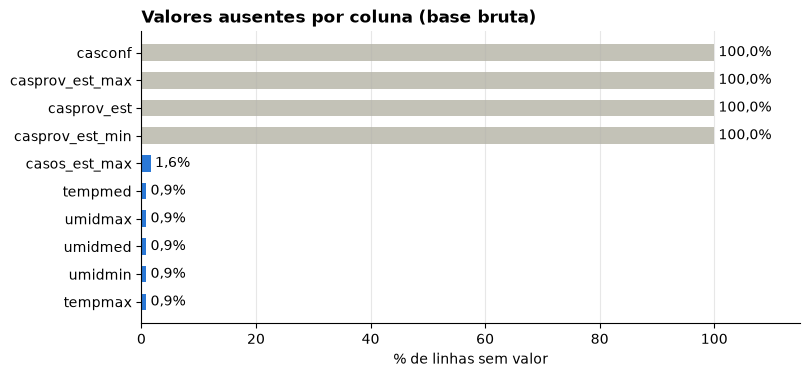

Semanas sem temperatura e umidade médias: [202049, 202050, 202051, 202052]


In [5]:
# Gráfico: percentual de valores ausentes nas colunas que têm algum
pct_ausentes = (df_bruto.isna().mean() * 100).sort_values()
pct_ausentes = pct_ausentes[pct_ausentes > 0]

fig, ax = plt.subplots(figsize=(8.5, 3.8))
barras = ax.barh(pct_ausentes.index, pct_ausentes.values,
                 color=['#c3c2b7' if v == 100 else '#2a78d6' for v in pct_ausentes.values], height=0.6)
ax.bar_label(barras, labels=[br(v, 1) + '%' for v in pct_ausentes.values], padding=3)
ax.set_xlim(0, 115)
ax.set_xlabel('% de linhas sem valor')
ax.grid(axis='y', visible=False)
ax.set_title('Valores ausentes por coluna (base bruta)', loc='left', fontweight='bold')
plt.show()

semanas_sem_clima = sorted(int(se) for se in df_bruto.loc[df_bruto['tempmed'].isna(), 'SE'].unique())
print('Semanas sem temperatura e umidade médias:', semanas_sem_clima)

In [6]:
# Checagens de consistência (só contam; não alteram a base)
d = df_bruto.assign(data_iniSE=pd.to_datetime(df_bruto['data_iniSE'])).sort_values(['municipio_nome', 'SE'])
intervalo_dias = d.groupby('municipio_nome')['data_iniSE'].diff().dt.days.dropna()

checagens = pd.DataFrame({'linhas encontradas': {
    'Linhas totalmente duplicadas': d.duplicated().sum(),
    'Duplicidade da chave (município, SE)': d.duplicated(['municipio_nome', 'SE']).sum(),
    'Semanas faltando na sequência (intervalo diferente de 7 dias)': (intervalo_dias != 7).sum(),
    'Casos notificados negativos': (d['casos'] < 0).sum(),
    'População menor ou igual a zero': (d['pop'] <= 0).sum(),
    'Temperatura média fora de 0 a 40 °C': (d['tempmed'].notna() & ~d['tempmed'].between(0, 40)).sum(),
    'Umidade média fora de 0 a 100%': (d['umidmed'].notna() & ~d['umidmed'].between(0, 100)).sum(),
    'nivel_inc diferente de 0, 1 ou 2': (~d['nivel_inc'].isin([0, 1, 2])).sum(),
}})
tabela(checagens, casas=0, titulo='Checagens de consistência da base bruta')

,linhas encontradas
Linhas totalmente duplicadas,0
"Duplicidade da chave (município, SE)",0
Semanas faltando na sequência (intervalo diferente de 7 dias),0
Casos notificados negativos,0
População menor ou igual a zero,0
Temperatura média fora de 0 a 40 °C,0
Umidade média fora de 0 a 100%,0
"nivel_inc diferente de 0, 1 ou 2",0


In [7]:
colunas_vazias = [c for c in df_bruto.columns if df_bruto[c].isna().all()]
colunas_constantes = [c for c in df_bruto.columns if df_bruto[c].nunique(dropna=True) == 1]
print('Colunas totalmente vazias:', colunas_vazias)
print('Colunas com um único valor:', ', '.join(f'{c} (sempre {df_bruto[c].iloc[0]})' for c in colunas_constantes))
print(f"Temperatura média: de {br(df_bruto['tempmed'].min(), 1)} a {br(df_bruto['tempmed'].max(), 1)} °C"
      f" | umidade média: de {br(df_bruto['umidmed'].min(), 1)} a {br(df_bruto['umidmed'].max(), 1)}%")

Colunas totalmente vazias: ['casprov_est', 'casprov_est_min', 'casprov_est_max', 'casconf']
Colunas com um único valor: Localidade_id (sempre 0)
Temperatura média: de 8,9 a 27,1 °C | umidade média: de 45,6 a 99,0%


<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura do diagnóstico**

- **Sem duplicidades, sem semanas faltando e sem valores impossíveis:** cada município tem uma linha por semana, com intervalo de 7 dias entre todas as semanas. Isso garante que o `shift` (2.3) traga sempre a semana certa.
- **Colunas sem informação:** `casprov_est`, `casprov_est_min`, `casprov_est_max` e `casconf` estão totalmente vazias, e `Localidade_id` vale sempre 0.
- **Clima ausente em 20 linhas:** a temperatura e a umidade faltam nas SE 49 a 52 de 2020, nos 5 municípios ao mesmo tempo.
- `casos_est_max` falta em 38 linhas, mas essa coluna não é usada.

</div>

### 2.3 Data wrangling (tratamento)

Cada transformação abaixo é registrada em uma tabela de log, com o motivo. Todas são **determinísticas e não aprendem nada com os dados** (remover colunas, converter tipos, ordenar, calcular a incidência e deslocar semanas), por isso podem ser feitas antes da divisão entre treino e teste sem vazamento. A única transformação que aprende com os dados, a padronização da regressão logística, é ajustada só no treino (seção 5.1).

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

**Data wrangling** é "arrumar a casa" antes de usar os dados: jogar fora o que não serve, colocar cada coisa no formato certo e criar as colunas que o modelo precisa. Anotamos cada passo para que qualquer pessoa consiga refazer o mesmo caminho.

</div>

In [8]:
log_tratamento = []


def registrar(passo, o_que, por_que, afetadas, base_atual):
    log_tratamento.append({'passo': passo, 'o que foi feito': o_que, 'por quê': por_que,
                           'afetadas': afetadas, 'linhas × colunas depois': f'{base_atual.shape[0]} × {base_atual.shape[1]}'})


df = df_bruto.copy()
registrar('0. Partida', 'Base bruta, sem alteração', '—', '—', df)

# Passo 1: colunas sem nenhuma informação
sem_informacao = colunas_vazias + colunas_constantes
df = df.drop(columns=sem_informacao)
registrar('1. Colunas vazias ou constantes', 'Removidas: ' + ', '.join(sem_informacao),
          'Não trazem nenhuma informação', f'{len(sem_informacao)} colunas', df)

# Passo 2: colunas que não entram na análise
COLUNAS_USADAS = ['data_iniSE', 'SE', 'municipio_nome', 'casos', 'casos_est', 'pop',
                  'tempmed', 'umidmed', 'nivel_inc', 'versao_modelo']
sem_uso = [c for c in df.columns if c not in COLUNAS_USADAS]
df = df[COLUNAS_USADAS].copy()
registrar('2. Colunas sem uso', 'Removidas: ' + ', '.join(sem_uso),
          'Repetem informação (Rt, nível e receptividade vêm dos próprios casos ou do clima; mínimas e máximas '
          'repetem a média) ou são identificadores', f'{len(sem_uso)} colunas', df)

# Passo 3: tipos e ordem
df['data_iniSE'] = pd.to_datetime(df['data_iniSE'])
df = df.sort_values(['municipio_nome', 'SE']).reset_index(drop=True)
registrar('3. Tipos e ordem', 'data_iniSE convertida de texto para data; base ordenada por município e semana',
          'O deslocamento de semanas (shift) depende da ordem correta', f'{len(df)} linhas', df)

# Passo 4: duplicidades
n_duplicadas = int(df.duplicated(['municipio_nome', 'SE']).sum())
df = df.drop_duplicates(['municipio_nome', 'SE']).reset_index(drop=True)
registrar('4. Duplicidades', 'Remoção de linhas repetidas para o mesmo município e semana',
          'Evita contar a mesma semana duas vezes', f'{n_duplicadas} linhas', df)

print('Colunas mantidas:', list(df.columns))
print('Linhas e colunas:', df.shape)

Colunas mantidas: ['data_iniSE', 'SE', 'municipio_nome', 'casos', 'casos_est', 'pop', 'tempmed', 'umidmed', 'nivel_inc', 'versao_modelo']
Linhas e colunas: (2305, 10)


**Passo 5 — semanas que ainda estão sendo atualizadas.** Os casos de uma semana continuam sendo notificados por algum tempo depois que ela termina (*atraso de notificação*). Para corrigir isso, o InfoDengue calcula `casos_est`. Quando `casos_est` é diferente de `casos`, a semana ainda não está fechada. Usar essas semanas faria o modelo aprender com valores que ainda vão mudar. Por isso removemos todas as semanas a partir da primeira em que isso acontece em algum dos municípios, para que os 5 fiquem com o mesmo período.

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

As últimas semanas ainda estão "em aberto": os números delas vão crescer, porque as notificações atrasam. É como uma conta que ainda não fechou. Por isso deixamos essas semanas de fora.

</div>

In [9]:
semanas_abertas = sorted(int(se) for se in df.loc[df['casos_est'] != df['casos'], 'SE'].unique())
print('Semanas em que a estimativa ainda difere dos casos notificados:', semanas_abertas)

primeira_aberta = semanas_abertas[0]
n_abertas = int((df['SE'] >= primeira_aberta).sum())
df = df[df['SE'] < primeira_aberta].reset_index(drop=True)
registrar('5. Semanas em aberto', f'Removidas as semanas a partir da SE {primeira_aberta}',
          'Ainda recebem notificações (casos_est diferente de casos): os valores vão mudar', f'{n_abertas} linhas', df)
print(f'Removidas {n_abertas} linhas. Ficamos com {len(df)} linhas, da SE {df["SE"].min()} até a SE {df["SE"].max()}.')

Semanas em que a estimativa ainda difere dos casos notificados: [202634, 202635, 202636, 202637, 202638, 202639, 202640, 202641, 202642, 202643]
Removidas 50 linhas. Ficamos com 2255 linhas, da SE 201801 até a SE 202633.


**Passo 6 — incidência por 100 mil habitantes.** São Paulo tem cerca de 12,2 milhões de habitantes e São Caetano do Sul, cerca de 167 mil. Comparar número de casos entre eles não faz sentido, por isso usamos a **incidência**: casos por 100 mil habitantes.

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

100 casos em São Caetano pesam muito mais do que 100 casos em São Paulo. A incidência coloca todo mundo na mesma régua: **"a cada 100 mil moradores, quantos tiveram dengue?"**

`incidência = casos ÷ população × 100.000`

</div>

In [10]:
print('População mais recente de cada município (IBGE, via InfoDengue):')
print(df.groupby('municipio_nome')['pop'].last().loc[MUNICIPIOS].apply(lambda p: br(p, 0)).to_string())

df['incidencia'] = df['casos'] / df['pop'] * 100_000
registrar('6. Incidência', 'Criada incidencia = casos ÷ população × 100.000',
          'Permite comparar municípios de tamanhos diferentes', '1 coluna nova', df)
tabela(df[['municipio_nome', 'SE', 'casos', 'pop', 'incidencia']].tail(), sem_milhar=['SE'],
       titulo='Últimas linhas, já com a incidência calculada')

População mais recente de cada município (IBGE, via InfoDengue):
municipio_nome
São Paulo                12.200.180
Osasco                      777.048
Santo André                 776.640
São Bernardo do Campo       832.347
São Caetano do Sul          166.847


,municipio_nome,SE,casos,pop,incidencia
2250,São Paulo,202629,1.119,12.200.180,"9,17"
2251,São Paulo,202630,1.144,12.200.180,"9,38"
2252,São Paulo,202631,1.199,12.200.180,"9,83"
2253,São Paulo,202632,1.092,12.200.180,"8,95"
2254,São Paulo,202633,1.269,12.200.180,"10,40"


**Passo 7 — variáveis de entrada e variáveis-alvo.** Tudo é calculado **dentro de cada município** (`groupby`), para que uma linha de Osasco nunca use dados de São Paulo.
- `shift(1)` e `shift(2)` trazem a incidência de 1 e 2 semanas **antes** (passado, que já é conhecido na semana t).
- `shift(-4)` traz a informação de 4 semanas **depois**, que é o que queremos prever. Ela só é usada como alvo, nunca como entrada.

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

Imagine uma linha do tempo de cada cidade. Para a semana de hoje, o `shift` **copia** valores de outras semanas para a mesma linha:
- da semana passada e da retrasada → viram **pistas**;
- de 4 semanas na frente → vira a **resposta certa** que o modelo tenta acertar.

</div>

In [11]:
HORIZONTE = 4  # semanas à frente

por_municipio = df.groupby('municipio_nome')

# Entradas (passado e presente)
df['incidencia_1sem_antes'] = por_municipio['incidencia'].shift(1)
df['incidencia_2sem_antes'] = por_municipio['incidencia'].shift(2)
df['acima_limiar_hoje'] = (df['nivel_inc'] == 2).astype(int)

# Alvos (futuro: semana t + 4) e a semana a que cada alvo se refere
df['incidencia_em_4_sem'] = por_municipio['incidencia'].shift(-HORIZONTE)
df['nivel_inc_em_4_sem'] = por_municipio['nivel_inc'].shift(-HORIZONTE)
df['SE_alvo'] = por_municipio['SE'].shift(-HORIZONTE)
df['data_alvo'] = por_municipio['data_iniSE'].shift(-HORIZONTE)
registrar('7. Defasagens e alvos', 'Criadas incidencia_1sem_antes, incidencia_2sem_antes e acima_limiar_hoje (entradas); '
          'incidencia_em_4_sem e nivel_inc_em_4_sem (alvos); SE_alvo e data_alvo (semana do alvo)',
          'As entradas usam só o passado; o futuro (t + 4) entra apenas como alvo', '7 colunas novas', df)

FEATURES_LINEAR = ['incidencia', 'incidencia_1sem_antes', 'incidencia_2sem_antes', 'tempmed', 'umidmed']
FEATURES_LOGISTICA = FEATURES_LINEAR + ['acima_limiar_hoje']

# Conferência: em São Paulo, o alvo da SE 201801 é a incidência da SE 201805 (4 semanas depois)
exemplo = df.loc[df['municipio_nome'] == 'São Paulo',
                 ['SE', 'incidencia', 'incidencia_1sem_antes', 'incidencia_2sem_antes', 'SE_alvo', 'incidencia_em_4_sem']].head(6)
tabela(exemplo, sem_milhar=['SE', 'SE_alvo'], titulo='Conferência do shift (São Paulo, primeiras semanas)')

,SE,incidencia,incidencia_1sem_antes,incidencia_2sem_antes,SE_alvo,incidencia_em_4_sem
1804,201801,"3,25",—,—,201805,"4,38"
1805,201802,"4,52","3,25",—,201806,"3,77"
1806,201803,"5,65","4,52","3,25",201807,"3,70"
1807,201804,"4,45","5,65","4,52",201808,"3,62"
1808,201805,"4,38","4,45","5,65",201809,"3,22"
1809,201806,"3,77","4,38","4,45",201810,"2,85"


**Passos 8 e 9 — linhas incompletas e alvo binário.** Ficam de fora as linhas sem as 2 semanas anteriores (início da série), sem a semana t + 4 (fim da série) e sem clima (SE 49 a 52 de 2020). O clima não foi imputado: são as mesmas 4 semanas seguidas nos 5 municípios ao mesmo tempo, então não há vizinho com dado para completar a lacuna com segurança. Por fim, criamos o alvo da regressão logística.

In [12]:
sem_historico = int(df[['incidencia_1sem_antes', 'incidencia_2sem_antes']].isna().any(axis=1).sum())
sem_alvo = int(df['incidencia_em_4_sem'].isna().sum())
sem_clima = int(df[['tempmed', 'umidmed']].isna().any(axis=1).sum())
print('Sem as 2 semanas anteriores (início da série):', sem_historico)
print('Sem a semana t + 4 (fim da série):', sem_alvo)
print('Sem temperatura/umidade (SE 49 a 52 de 2020):', sem_clima)

# df continua com a série semanal completa (usada nos gráficos da seção 3);
# base é a base de modelagem, só com linhas completas
base = df.dropna(subset=FEATURES_LINEAR + ['incidencia_em_4_sem', 'nivel_inc_em_4_sem']).copy()
registrar('8. Linhas incompletas', f'Removidas {len(df) - len(base)} linhas: {sem_historico} sem histórico, '
          f'{sem_alvo} sem alvo e {sem_clima} sem clima', 'O modelo precisa de todas as entradas e do alvo',
          f'{len(df) - len(base)} linhas', base)

base['nivel_inc_em_4_sem'] = base['nivel_inc_em_4_sem'].astype(int)
base['SE_alvo'] = base['SE_alvo'].astype(int)
base['epidemica_em_4_sem'] = (base['nivel_inc_em_4_sem'] == 2).astype(int)
registrar('9. Alvo binário', 'Criada epidemica_em_4_sem = 1 se nivel_inc_em_4_sem = 2; SE_alvo e nível como inteiros',
          'Alvo da regressão logística', '1 coluna nova', base)
print(f'\nBase de modelagem: {len(base)} linhas (de {len(df)})')

Sem as 2 semanas anteriores (início da série): 10
Sem a semana t + 4 (fim da série): 20
Sem temperatura/umidade (SE 49 a 52 de 2020): 20

Base de modelagem: 2205 linhas (de 2255)


In [13]:
# Log completo do tratamento
tabela(pd.DataFrame(log_tratamento), esconder_indice=True, titulo='Log do data wrangling: o que foi feito em cada passo')

passo,o que foi feito,por quê,afetadas,linhas × colunas depois
0. Partida,"Base bruta, sem alteração",—,—,2305 × 30
1. Colunas vazias ou constantes,"Removidas: casprov_est, casprov_est_min, casprov_est_max, casconf, Localidade_id",Não trazem nenhuma informação,5 colunas,2305 × 25
2. Colunas sem uso,"Removidas: casos_est_min, casos_est_max, p_rt1, p_inc100k, nivel, id, Rt, tempmin, umidmax, receptivo, transmissao, umidmin, tempmax, casprov, notif_accum_year","Repetem informação (Rt, nível e receptividade vêm dos próprios casos ou do clima; mínimas e máximas repetem a média) ou são identificadores",15 colunas,2305 × 10
3. Tipos e ordem,data_iniSE convertida de texto para data; base ordenada por município e semana,O deslocamento de semanas (shift) depende da ordem correta,2305 linhas,2305 × 10
4. Duplicidades,Remoção de linhas repetidas para o mesmo município e semana,Evita contar a mesma semana duas vezes,0 linhas,2305 × 10
5. Semanas em aberto,Removidas as semanas a partir da SE 202634,Ainda recebem notificações (casos_est diferente de casos): os valores vão mudar,50 linhas,2255 × 10
6. Incidência,Criada incidencia = casos ÷ população × 100.000,Permite comparar municípios de tamanhos diferentes,1 coluna nova,2255 × 11
7. Defasagens e alvos,"Criadas incidencia_1sem_antes, incidencia_2sem_antes e acima_limiar_hoje (entradas); incidencia_em_4_sem e nivel_inc_em_4_sem (alvos); SE_alvo e data_alvo (semana do alvo)",As entradas usam só o passado; o futuro (t + 4) entra apenas como alvo,7 colunas novas,2255 × 18
8. Linhas incompletas,"Removidas 50 linhas: 10 sem histórico, 20 sem alvo e 20 sem clima",O modelo precisa de todas as entradas e do alvo,50 linhas,2205 × 18
9. Alvo binário,Criada epidemica_em_4_sem = 1 se nivel_inc_em_4_sem = 2; SE_alvo e nível como inteiros,Alvo da regressão logística,1 coluna nova,2205 × 19


### 2.4 Valores atípicos (outliers)

Usamos a regra do **IQR** (intervalo interquartil), calculada **separadamente para cada município**: uma semana é atípica quando a incidência passa de Q3 + 1,5 × IQR, sendo IQR = Q3 − Q1. A regra é aplicada por município porque o nível típico de cada cidade é diferente.

In [14]:
linhas_iqr = []
atipicas = []
for mun in MUNICIPIOS:
    inc = df.loc[df['municipio_nome'] == mun, ['SE', 'incidencia']]
    q1, q3 = inc['incidencia'].quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    acima = inc[inc['incidencia'] > limite]
    atipicas.append(acima.assign(municipio_nome=mun))
    linhas_iqr.append({'município': mun, 'Q1': q1, 'Q3': q3, 'limite superior': limite,
                       'semanas atípicas': len(acima),
                       'em 2024': int((acima['SE'] // 100 == 2024).sum()),
                       'em 2025': int((acima['SE'] // 100 == 2025).sum())})
tabela_iqr = pd.DataFrame(linhas_iqr).set_index('município')
atipicas = pd.concat(atipicas)
total_atipicas = len(atipicas)
em_2024_2025 = int(atipicas['SE'].floordiv(100).isin([2024, 2025]).sum())
print(f'Semanas atípicas: {total_atipicas} de {len(df)} | {em_2024_2025} delas em 2024 ou 2025 '
      f'({br(100 * em_2024_2025 / total_atipicas, 1)}%)')
tabela(tabela_iqr, titulo='Regra do IQR na incidência semanal, por município')

Semanas atípicas: 283 de 2255 | 247 delas em 2024 ou 2025 (87,3%)


,Q1,Q3,limite superior,semanas atípicas,em 2024,em 2025
município,,,,,,
São Paulo,"2,13","21,63","50,87",45,26,19
Osasco,"0,57","6,95","16,52",62,24,26
Santo André,"0,40","1,94","4,25",69,28,21
São Bernardo do Campo,"1,54","7,93","17,53",47,25,21
São Caetano do Sul,"1,20","6,99","15,68",60,35,22


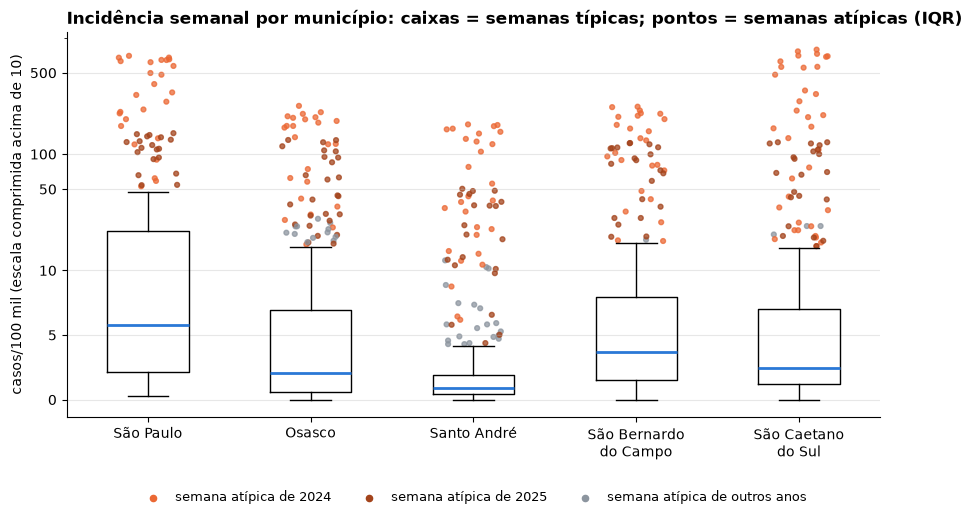

In [15]:
# Boxplot por município (mesma regra do IQR da tabela) com as semanas atípicas coloridas pelo ano
fig, ax = plt.subplots(figsize=(10.5, 5))
ax.boxplot([df.loc[df['municipio_nome'] == m, 'incidencia'] for m in MUNICIPIOS],
           widths=0.5, showfliers=False, medianprops=dict(color='#2a78d6', linewidth=2))
ax.set_xticks(range(1, len(MUNICIPIOS) + 1), [m.replace(' do ', '\ndo ') for m in MUNICIPIOS])
COR_ANO = {2024: '#eb6834', 2025: '#a3431b'}
sorteio = np.random.default_rng(0)  # só espalha os pontos na horizontal para não ficarem sobrepostos
for posicao, mun in enumerate(MUNICIPIOS, start=1):
    pontos = atipicas[atipicas['municipio_nome'] == mun]
    ax.scatter(posicao + sorteio.uniform(-0.18, 0.18, len(pontos)), pontos['incidencia'], s=12, alpha=0.75,
               c=[COR_ANO.get(ano, '#8c959f') for ano in pontos['SE'] // 100])
ax.set_yscale('symlog', linthresh=10)
ax.set_yticks([0, 5, 10, 50, 100, 500], ['0', '5', '10', '50', '100', '500'])
for ano, cor in [(2024, '#eb6834'), (2025, '#a3431b'), ('outros anos', '#8c959f')]:
    ax.scatter([], [], c=cor, s=20, label=f'semana atípica de {ano}' if ano != 'outros anos' else 'semana atípica de outros anos')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9)
ax.set_ylabel('casos/100 mil (escala comprimida acima de 10)')
ax.grid(axis='x', visible=False)
ax.set_title('Incidência semanal por município: caixas = semanas típicas; pontos = semanas atípicas (IQR)',
             loc='left', fontweight='bold')
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura e decisão**

- São **283** semanas atípicas pela regra do IQR, e **247** delas (87,3%) são de 2024 ou 2025, os anos de epidemia forte.
- **Decisão: os valores atípicos foram mantidos.** Eles não são erros de digitação: são as epidemias reais, justamente o que queremos antecipar. Remover essas semanas esconderia os momentos mais importantes para a vigilância.
- Consequência: os picos pesam muito na regressão linear e no RMSE. Levamos isso em conta na interpretação (seções 4 e 6).

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

Para cada cidade, a caixa mostra onde está a "maioria normal" das semanas, e os pontos são as semanas muito fora do comum pela regra do IQR. Quase todos os pontos são laranja (2024) ou marrom (2025): foram anos de epidemia, não erros nos dados. O eixo vertical é comprimido acima de 10 para caberem cidades com níveis muito diferentes.

</div>

### 2.5 Conferência da base tratada

In [16]:
assert not base.duplicated(['municipio_nome', 'SE']).any()
assert base[FEATURES_LOGISTICA + ['incidencia_em_4_sem', 'epidemica_em_4_sem']].notna().all().all()
print(f'Base tratada: {base.shape[0]} linhas × {base.shape[1]} colunas | {base["municipio_nome"].nunique()} municípios'
      f' | semanas t de {base["SE"].min()} a {base["SE"].max()}')
print('Valores ausentes nas entradas e nos alvos:', int(base[FEATURES_LOGISTICA + ['incidencia_em_4_sem', 'epidemica_em_4_sem']].isna().sum().sum()))
print('Duplicidades (município, SE):', int(base.duplicated(['municipio_nome', 'SE']).sum()))
print('Linhas por município:', base['municipio_nome'].value_counts().loc[MUNICIPIOS].to_dict())

estatisticas = base[FEATURES_LOGISTICA + ['incidencia_em_4_sem', 'epidemica_em_4_sem']].describe().T
estatisticas = estatisticas.rename(columns={'count': 'linhas', 'mean': 'média', 'std': 'desvio-padrão', 'min': 'mínimo',
                                            '25%': 'Q1', '50%': 'mediana', '75%': 'Q3', 'max': 'máximo'})
estatisticas['linhas'] = estatisticas['linhas'].astype(int)
tabela(estatisticas, titulo='Estatísticas descritivas das variáveis do modelo (base tratada)')

Base tratada: 2205 linhas × 19 colunas | 5 municípios | semanas t de 201803 a 202629
Valores ausentes nas entradas e nos alvos: 0
Duplicidades (município, SE): 0
Linhas por município: {'São Paulo': 441, 'Osasco': 441, 'Santo André': 441, 'São Bernardo do Campo': 441, 'São Caetano do Sul': 441}


,linhas,média,desvio-padrão,mínimo,Q1,mediana,Q3,máximo
incidencia,2.205,"20,15","72,78","0,00","0,86","2,47","8,29","791,14"
incidencia_1sem_antes,2.205,"20,15","72,78","0,00","0,86","2,47","8,29","791,14"
incidencia_2sem_antes,2.205,"20,15","72,78","0,00","0,86","2,47","8,29","791,14"
tempmed,2.205,"19,43","2,81","8,94","17,36","19,74","21,44","27,09"
umidmed,2.205,"80,50","7,83","45,58","75,74","81,08","85,51","98,96"
acima_limiar_hoje,2.205,"0,21","0,40","0,00","0,00","0,00","0,00","1,00"
incidencia_em_4_sem,2.205,"20,15","72,79","0,00","0,86","2,47","8,41","791,14"
epidemica_em_4_sem,2.205,"0,20","0,40","0,00","0,00","0,00","0,00","1,00"


### 2.6 Separação entre treino e teste, sem vazamento de dados

Como os dados são uma **série temporal**, a divisão é feita **pelo tempo**, e não por sorteio. No sorteio, semanas vizinhas cairiam uma no treino e outra no teste, e o modelo "veria o futuro".

- **Treino:** linhas cuja semana-alvo (t + 4) é de 2018 a 2024.
- **Teste:** linhas cuja semana-alvo é de 2025 em diante (até a última semana fechada de 2026).

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Cuidados para evitar vazamento de dados**

1. As entradas usam só informação da semana t e de antes. O futuro aparece somente no alvo.
2. A divisão é feita pela **semana-alvo**: nenhum alvo do treino pertence ao período de teste (conferido com `assert` abaixo).
3. Defasagens e alvos são calculados dentro de cada município.
4. O data wrangling (2.3) só tem passos que não aprendem com os dados. Na logística, o `StandardScaler` (padronização) aprende média e desvio-padrão **somente no treino** e depois só é aplicado ao teste.
5. As semanas ainda abertas (passo 5 do tratamento) foram removidas.
6. Os gráficos que relacionam variáveis com os alvos (seções 3.3 a 3.5) usam **só o treino**.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

É como uma prova: o modelo **estuda** com 2018 a 2024 e depois faz a **prova** com 2025 e 2026, que ele nunca viu. Se misturássemos as semanas, ele poderia "colar", olhando semanas do futuro, e a nota sairia boa demais para ser verdade.

</div>

In [17]:
base['conjunto'] = np.where(base['SE_alvo'] < 202501, 'treino', 'teste')
treino = base[base['conjunto'] == 'treino'].copy()
teste = base[base['conjunto'] == 'teste'].copy()

# Verificações de que não há vazamento
assert treino['SE_alvo'].max() < teste['SE_alvo'].min()        # nenhum alvo do treino está no período de teste
assert set(treino.index).isdisjoint(teste.index)                # nenhuma linha nos dois conjuntos
assert len(treino) + len(teste) == len(base)

print(f"Treino: {len(treino)} linhas | semanas-alvo de {treino['SE_alvo'].min()} a {treino['SE_alvo'].max()}")
print(f"Teste:  {len(teste)} linhas | semanas-alvo de {teste['SE_alvo'].min()} a {teste['SE_alvo'].max()}")
print(f"Teste = {br(100 * len(teste) / len(base), 1)}% da base")
print(f"Semanas epidêmicas (alvo = 1): treino {br(100 * treino['epidemica_em_4_sem'].mean(), 1)}%"
      f" | teste {br(100 * teste['epidemica_em_4_sem'].mean(), 1)}%")
print('Verificações de vazamento: OK')

Treino: 1775 linhas | semanas-alvo de 201807 a 202452
Teste:  430 linhas | semanas-alvo de 202501 a 202633
Teste = 19,5% da base
Semanas epidêmicas (alvo = 1): treino 18,4% | teste 28,6%
Verificações de vazamento: OK


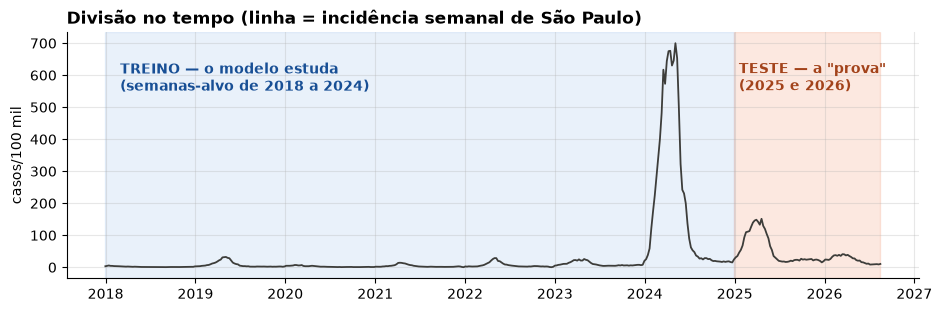

In [18]:
# Linha do tempo da divisão (exemplo com São Paulo)
sp = df[df['municipio_nome'] == 'São Paulo']
inicio_teste = teste['data_alvo'].min()

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axvspan(sp['data_iniSE'].min(), inicio_teste, color='#2a78d6', alpha=0.10)
ax.axvspan(inicio_teste, sp['data_iniSE'].max(), color='#eb6834', alpha=0.15)
ax.plot(sp['data_iniSE'], sp['incidencia'], color='#3d3d3a', linewidth=1.3)
topo = sp['incidencia'].max()
ax.text(pd.Timestamp('2018-03-01'), topo * 0.92, 'TREINO — o modelo estuda\n(semanas-alvo de 2018 a 2024)',
        color='#184f95', fontweight='bold', va='top')
ax.text(inicio_teste + pd.Timedelta(days=20), topo * 0.92, 'TESTE — a "prova"\n(2025 e 2026)',
        color='#a3431b', fontweight='bold', va='top')
ax.set_ylabel('casos/100 mil')
ax.set_title('Divisão no tempo (linha = incidência semanal de São Paulo)', loc='left', fontweight='bold')
plt.show()

**Validação cruzada no tempo (dentro do treino).** O teste é usado uma única vez, no fim. Para escolher o limiar de alerta, ver se o desempenho é estável de um ano para outro e testar a hipótese, usamos **validação cruzada no tempo** só com o treino: em cada rodada, o modelo treina com as semanas-alvo dos anos anteriores e é avaliado no ano seguinte (validação). São 5 rodadas, validando em 2020, 2021, 2022, 2023 e 2024. Como a validação vem sempre depois do treino da rodada, nenhuma rodada usa dados do futuro.

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

É como fazer **simulados** antes da prova: o modelo estuda até 2019 e faz o simulado de 2020; depois estuda até 2020 e faz o de 2021; e assim por diante. As escolhas, como o limiar do alerta, são feitas com os simulados. Só depois o modelo faz a prova de verdade, o teste de 2025–2026.

</div>

In [19]:
# Validação cruzada no tempo: 5 rodadas dentro do treino (a janela de treino cresce a cada ano)
ANOS_VALIDACAO = [2020, 2021, 2022, 2023, 2024]
ano_alvo = treino['SE_alvo'] // 100
RODADAS = []
for ano in ANOS_VALIDACAO:
    idx_estudo = treino.index[ano_alvo < ano]
    idx_validacao = treino.index[ano_alvo == ano]
    assert treino.loc[idx_estudo, 'SE_alvo'].max() < treino.loc[idx_validacao, 'SE_alvo'].min()  # nada do futuro
    RODADAS.append((ano, idx_estudo, idx_validacao))

tabela_rodadas = pd.DataFrame([{
    'rodada': i + 1,
    'treina com semanas-alvo de': f'2018 a {ano - 1}',
    'valida em': str(ano),
    'linhas de treino': len(idx_e),
    'linhas de validação': len(idx_v),
    'semanas epidêmicas na validação': int(treino.loc[idx_v, 'epidemica_em_4_sem'].sum()),
} for i, (ano, idx_e, idx_v) in enumerate(RODADAS)])
tabela(tabela_rodadas, esconder_indice=True, titulo='Rodadas da validação cruzada no tempo (só treino)')

rodada,treina com semanas-alvo de,valida em,linhas de treino,linhas de validação,semanas epidêmicas na validação
1,2018 a 2019,2020,490,260,20
2,2018 a 2020,2021,750,245,2
3,2018 a 2021,2022,995,260,14
4,2018 a 2022,2023,1.255,260,27
5,2018 a 2023,2024,1.515,260,176


### 2.7 Exportação da base tratada

A base de modelagem, já tratada e com a indicação de treino ou teste, é salva em **`dengue_base_tratada.csv`**, na mesma pasta do notebook. O painel Streamlit (`app.py`) usa este arquivo.

| Coluna | Conteúdo |
|---|---|
| `municipio_nome`, `SE`, `data_iniSE` | município e semana t |
| `pop`, `casos`, `incidencia` | população, casos notificados e incidência da semana t |
| `incidencia_1sem_antes`, `incidencia_2sem_antes` | incidência nas semanas t − 1 e t − 2 |
| `tempmed`, `umidmed` | temperatura e umidade médias da semana t |
| `nivel_inc`, `acima_limiar_hoje` | classificação do InfoDengue na semana t e indicador 0/1 de semana acima do limiar |
| `SE_alvo`, `data_alvo` | semana t + 4, a que o alvo se refere |
| `incidencia_em_4_sem` | alvo da regressão linear |
| `nivel_inc_em_4_sem`, `epidemica_em_4_sem` | classificação da semana t + 4 e alvo da regressão logística |
| `conjunto` | `treino` ou `teste` |

In [20]:
COLUNAS_EXPORTADAS = ['municipio_nome', 'SE', 'data_iniSE', 'pop', 'casos', 'incidencia',
                      'incidencia_1sem_antes', 'incidencia_2sem_antes', 'tempmed', 'umidmed',
                      'nivel_inc', 'acima_limiar_hoje', 'SE_alvo', 'data_alvo',
                      'incidencia_em_4_sem', 'nivel_inc_em_4_sem', 'epidemica_em_4_sem', 'conjunto']
ARQUIVO_TRATADO = 'dengue_base_tratada.csv'
base[COLUNAS_EXPORTADAS].to_csv(ARQUIVO_TRATADO, index=False, date_format='%Y-%m-%d')

# Conferência: relê o arquivo salvo e compara com a base em memória
relida = pd.read_csv(ARQUIVO_TRATADO)
assert relida.shape == (len(base), len(COLUNAS_EXPORTADAS))
assert np.allclose(relida['incidencia_em_4_sem'], base['incidencia_em_4_sem'])
print(f'Arquivo salvo: {ARQUIVO_TRATADO} | {relida.shape[0]} linhas × {relida.shape[1]} colunas')
print('Linhas por conjunto:', relida['conjunto'].value_counts().to_dict())
relida.head(3)

Arquivo salvo: dengue_base_tratada.csv | 2205 linhas × 18 colunas
Linhas por conjunto: {'treino': 1775, 'teste': 430}


,municipio_nome,SE,data_iniSE,pop,casos,incidencia,incidencia_1sem_antes,incidencia_2sem_antes,tempmed,umidmed,nivel_inc,acima_limiar_hoje,SE_alvo,data_alvo,incidencia_em_4_sem,nivel_inc_em_4_sem,epidemica_em_4_sem,conjunto
0,Osasco,201803,2018-01-14,699944,15,2.143029,1.000080,0.857211,21.892857,89.330475,1,0,201807,2018-02-11,1.142949,1,0,treino
1,Osasco,201804,2018-01-21,699944,18,2.571634,2.143029,1.000080,21.311905,92.759438,1,0,201808,2018-02-18,1.142949,1,0,treino
2,Osasco,201805,2018-01-28,699944,11,1.571554,2.571634,2.143029,19.385714,95.356790,1,0,201809,2018-02-25,0.571474,0,0,treino


---
<a id="secao3"></a>
## 3. Visualizações (análise exploratória)

As seções 3.1 e 3.2 descrevem a série completa. As seções 3.3 a 3.5 relacionam as variáveis com os alvos e usam **só o treino**, para que o período de teste não influencie nenhuma leitura.

### 3.1 Casos notificados por ano e incidência semanal

Observação: 2026 vai só até a SE 33 (última semana fechada).

In [21]:
casos_por_ano = (df.assign(ano=df['SE'] // 100)
                   .pivot_table(index='ano', columns='municipio_nome', values='casos', aggfunc='sum')
                   [MUNICIPIOS])
tabela(casos_por_ano, casas=0, titulo='Casos de dengue notificados por ano')

municipio_nome,São Paulo,Osasco,Santo André,São Bernardo do Campo,São Caetano do Sul
ano,,,,,
2018,10.920,152,283,888,96
2019,54.038,986,969,2.535,381
2020,16.082,417,120,1.117,86
2021,25.215,277,186,1.195,216
2022,43.287,908,499,1.083,322
2023,65.854,2.704,877,1.619,372
2024,1.263.604,25.809,16.646,29.642,16.658
2025,354.478,13.913,4.402,15.420,2.937
2026,96.602,2.502,224,2.098,184


Maior incidência semanal em 2024 (casos por 100 mil hab.):
municipio_nome
São Paulo                699,9
Osasco                   260,0
Santo André              180,1
São Bernardo do Campo    255,8
São Caetano do Sul       791,1


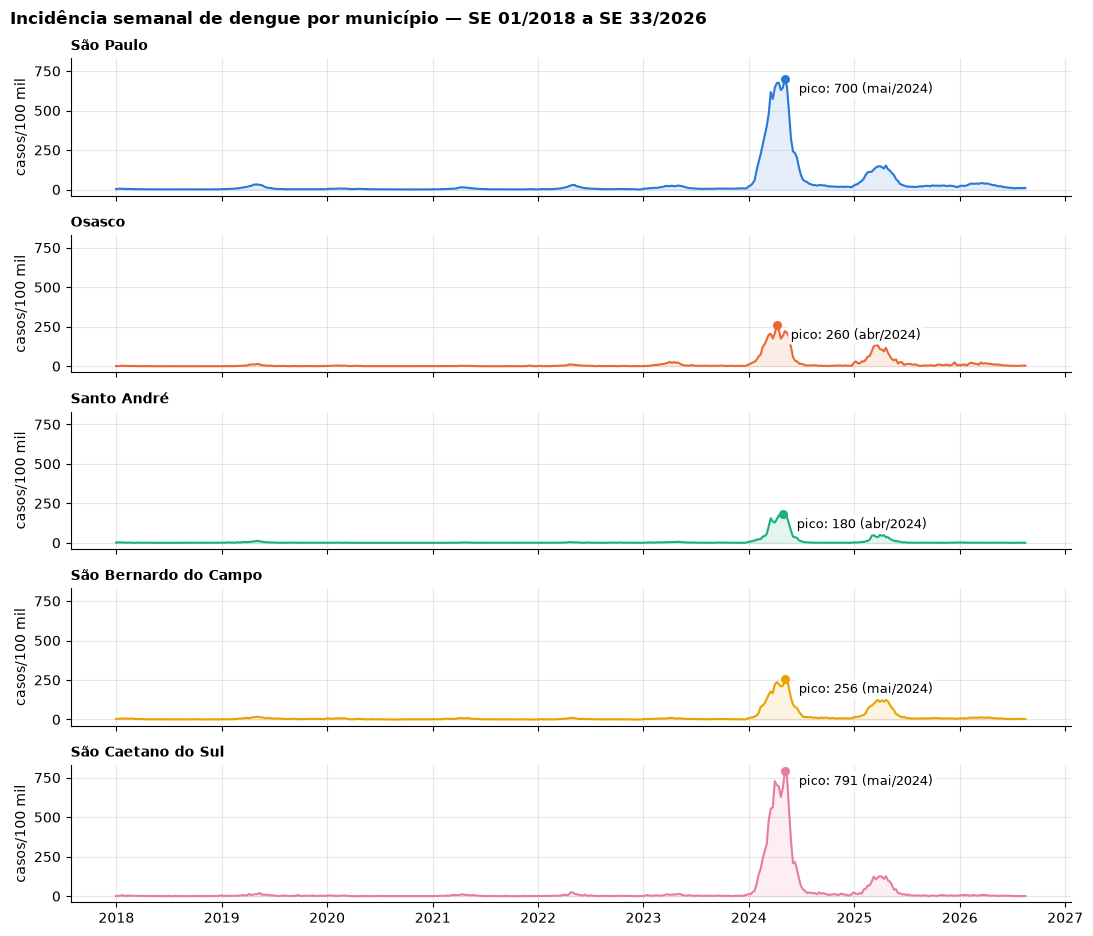

In [22]:
print('Maior incidência semanal em 2024 (casos por 100 mil hab.):')
print(df[df['SE'] // 100 == 2024].groupby('municipio_nome')['incidencia'].max().loc[MUNICIPIOS].apply(lambda v: br(v, 1)).to_string())

fig, eixos = plt.subplots(len(MUNICIPIOS), 1, figsize=(11, 9.5), sharex=True, sharey=True)
for ax, mun in zip(eixos, MUNICIPIOS):
    d = df[df['municipio_nome'] == mun]
    ax.plot(d['data_iniSE'], d['incidencia'], color=CORES[mun], linewidth=1.5)
    ax.fill_between(d['data_iniSE'], d['incidencia'], color=CORES[mun], alpha=0.12)
    # marca o pico de cada município
    pico = d.loc[d['incidencia'].idxmax()]
    ax.scatter(pico['data_iniSE'], pico['incidencia'], color=CORES[mun], s=30, zorder=3)
    ax.annotate(f"pico: {br(pico['incidencia'], 0)} ({MESES[pico['data_iniSE'].month - 1]}/{pico['data_iniSE'].year})",
                xy=(pico['data_iniSE'], pico['incidencia']), xytext=(10, -2), textcoords='offset points',
                fontsize=9, va='top', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.9))
    ax.set_title(mun, loc='left', fontsize=10, fontweight='bold')
    ax.set_ylabel('casos/100 mil')
ultima_se = df['SE'].max()
fig.suptitle(f'Incidência semanal de dengue por município — SE 01/2018 a SE {ultima_se % 100}/{ultima_se // 100}',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como ler o gráfico**

Cada faixa é uma cidade. Quanto mais alta a linha, mais casos por 100 mil moradores naquela semana. Todas as faixas usam a **mesma escala**, então dá para comparar a altura dos picos entre as cidades.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **2024 foi o ano com mais casos notificados** nos 5 municípios (só São Paulo teve 1.263.604), e **2025 foi o segundo**.
- Na maioria dos anos, o pico de incidência acontece **entre março e maio**.
- A incidência permite comparar cidades de tamanhos diferentes: São Caetano do Sul teve muito menos casos que São Paulo em 2024, mas seu pico semanal de incidência foi maior (cerca de 791 contra 700 casos por 100 mil).

</div>

### 3.2 O limiar epidêmico do InfoDengue muda com o tempo

O InfoDengue define um limiar epidêmico para cada município e o recalcula com o passar do tempo. A tabela mostra, para cada ano, a **menor incidência semanal que o InfoDengue classificou como acima do limiar epidêmico** (— = nenhuma semana acima do limiar naquele ano).

In [23]:
menor_inc_epidemica = (df[df['nivel_inc'] == 2]
                       .assign(ano=lambda d: d['SE'] // 100)
                       .pivot_table(index='ano', columns='municipio_nome', values='incidencia', aggfunc='min')
                       .reindex(columns=MUNICIPIOS))

versoes_teste = df.loc[df['SE'] >= 202501, 'versao_modelo']
print('Versão do modelo InfoDengue que gerou as classificações das semanas de 2025–2026:',
      versoes_teste.min(), 'a', versoes_teste.max())
tabela(menor_inc_epidemica, casas=1, titulo='Menor incidência semanal classificada como epidêmica, por ano')

Versão do modelo InfoDengue que gerou as classificações das semanas de 2025–2026: 2026-01-07 a 2026-11-03


municipio_nome,São Paulo,Osasco,Santo André,São Bernardo do Campo,São Caetano do Sul
ano,,,,,
2018,"5,6",—,—,"4,9",—
2019,"5,4","4,0","3,6","4,1","6,8"
2020,"5,6","4,0",—,"4,5",—
2021,"13,8",—,—,—,—
2022,"15,3","10,4",—,—,"14,2"
2023,"14,0","11,6","7,5",—,"12,6"
2024,"15,2","10,8","6,2","15,3","12,6"
2025,"24,4","17,0","9,8","17,2","16,2"
2026,"35,2","15,4",—,—,—


<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

Em São Paulo, a menor incidência considerada epidêmica era de **5,4 a 5,6** casos por 100 mil em 2018–2020, ficou entre **13,8 e 15,3** em 2021–2024 e chegou a **24,4 em 2025** e **35,2 em 2026**. Ou seja, a mesma incidência pode ser epidêmica num ano e não ser no outro. Por isso a regressão logística também recebe `acima_limiar_hoje`, que diz se o município já está acima do limiar em vigor na semana t.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

A "linha vermelha" que define epidemia **sobe** depois de anos com muitos casos. Um número que era alarmante em 2019 pode ser considerado normal em 2025. Por isso o modelo precisa saber se a cidade **já está** acima da linha hoje.

</div>

### 3.3 Distribuição das variáveis-alvo (treino)

incidencia_em_4_sem no treino: mediana 1,94 | média 19,18 | máximo 791,14 | assimetria (skew) 6,66
Semanas epidêmicas no treino, por município (%): {'São Paulo': '28,5', 'Osasco': '15,8', 'Santo André': '12,1', 'São Bernardo do Campo': '18,9', 'São Caetano do Sul': '16,6'}


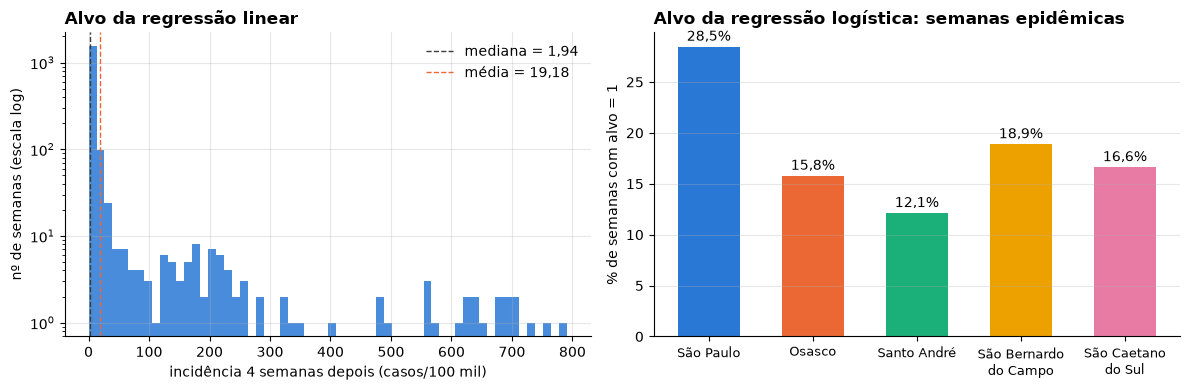

In [24]:
alvo_lin = treino['incidencia_em_4_sem']
print(f"incidencia_em_4_sem no treino: mediana {br(alvo_lin.median())} | média {br(alvo_lin.mean())}"
      f" | máximo {br(alvo_lin.max())} | assimetria (skew) {br(alvo_lin.skew())}")
pct_epid = (treino.groupby('municipio_nome')['epidemica_em_4_sem'].mean() * 100).loc[MUNICIPIOS]
print('Semanas epidêmicas no treino, por município (%):', pct_epid.apply(lambda v: br(v, 1)).to_dict())

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].hist(alvo_lin, bins=60, color='#2a78d6', alpha=0.85)
eixos[0].set_yscale('log')
eixos[0].axvline(alvo_lin.median(), color='#3d3d3a', linestyle='--', linewidth=1, label=f'mediana = {br(alvo_lin.median())}')
eixos[0].axvline(alvo_lin.mean(), color='#eb6834', linestyle='--', linewidth=1, label=f'média = {br(alvo_lin.mean())}')
eixos[0].legend(frameon=False)
eixos[0].set_xlabel('incidência 4 semanas depois (casos/100 mil)')
eixos[0].set_ylabel('nº de semanas (escala log)')
eixos[0].set_title('Alvo da regressão linear', loc='left', fontweight='bold')

barras = eixos[1].bar(range(len(MUNICIPIOS)), pct_epid.values, color=[CORES[m] for m in MUNICIPIOS], width=0.6)
eixos[1].bar_label(barras, labels=[br(v, 1) + '%' for v in pct_epid.values], padding=2)
eixos[1].set_xticks(range(len(MUNICIPIOS)), [m.replace(' do ', '\ndo ') for m in MUNICIPIOS], fontsize=9)
eixos[1].set_ylabel('% de semanas com alvo = 1')
eixos[1].grid(axis='x', visible=False)
eixos[1].set_title('Alvo da regressão logística: semanas epidêmicas', loc='left', fontweight='bold')
fig.tight_layout()
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **Alvo da linear muito assimétrico:** a mediana é 1,94 caso por 100 mil, mas a média é 19,18, puxada pelas semanas extremas (máximo de 791,14). A maioria das semanas tem incidência baixa, e poucas semanas de epidemia concentram os valores altos. Por isso os erros grandes ficam nos picos.
- **Alvo da logística desbalanceado:** só uma parte das semanas é epidêmica, de 12,1% em Santo André a 28,5% em São Paulo. Por isso olhamos precisão, recall e F1, e não só a acurácia (seção 5).

</div>

### 3.4 Clima e incidência 4 semanas depois (treino)

            incidência mediana em 4 semanas  semanas
tempmed                                             
até 16                                 1,15      254
16 a 18                                1,32      274
18 a 20                                1,78      428
20 a 22                                2,57      519
22 a 24                                4,37      248
acima de 24                            3,36       52


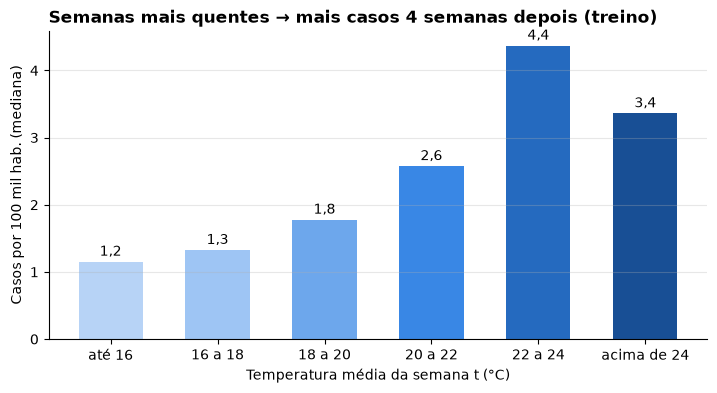

In [25]:
faixas_temp = pd.cut(treino['tempmed'], bins=[0, 16, 18, 20, 22, 24, 40],
                     labels=['até 16', '16 a 18', '18 a 20', '20 a 22', '22 a 24', 'acima de 24'])
por_faixa = treino.groupby(faixas_temp, observed=True)['incidencia_em_4_sem'].agg(['median', 'count'])
por_faixa.columns = ['incidência mediana em 4 semanas', 'semanas']
print(por_faixa.assign(**{'incidência mediana em 4 semanas':
                          por_faixa['incidência mediana em 4 semanas'].apply(lambda v: br(v, 2))}).to_string())

fig, ax = plt.subplots(figsize=(8.5, 4))
cores_barras = ['#b7d3f6', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95']  # mais quente = mais escuro
barras = ax.bar(por_faixa.index.astype(str), por_faixa['incidência mediana em 4 semanas'], color=cores_barras, width=0.6)
ax.bar_label(barras, labels=[br(v, 1) for v in por_faixa['incidência mediana em 4 semanas']], padding=2)
ax.set_xlabel('Temperatura média da semana t (°C)')
ax.set_ylabel('Casos por 100 mil hab. (mediana)')
ax.set_title('Semanas mais quentes → mais casos 4 semanas depois (treino)', loc='left', fontweight='bold')
ax.grid(axis='x', visible=False)
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como ler o gráfico**

Separamos as semanas do treino por faixa de temperatura. A altura de cada barra é a incidência **típica** (mediana) **4 semanas depois**. Usamos a mediana, e não a média, para que os picos extremos de 2024 não distorçam a comparação.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

A incidência mediana 4 semanas depois sobe de **1,15** caso por 100 mil nas semanas mais frias (até 16 °C) para **4,37** nas semanas entre 22 e 24 °C, de acordo com a hipótese. A faixa acima de 24 °C fica um pouco abaixo (3,36), mas tem só 52 semanas.

</div>

### 3.5 Matriz de correlação (treino)

A matriz mostra a correlação entre todas as variáveis de entrada e os dois alvos, calculada só com o treino. Usamos dois tipos:
- **Pearson:** mede relação em **linha reta**, que é o que a regressão linear usa.
- **Spearman:** mede se as variáveis **sobem e descem juntas**, mesmo que não em linha reta. Usa a ordem dos valores, então é menos afetada pelos picos de 2024.

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

**Correlação** vai de −1 a 1. Perto de 1 = as duas coisas sobem juntas; perto de −1 = quando uma sobe, a outra desce; perto de 0 = quase não têm relação. Quanto mais forte a cor, mais forte a relação.

</div>

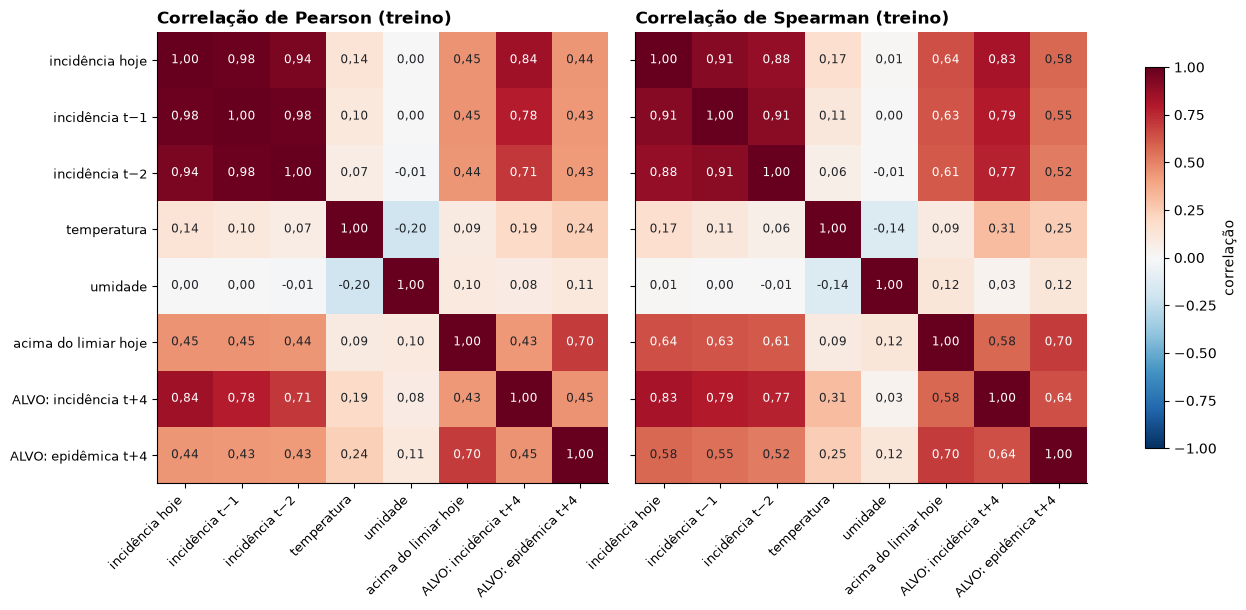

Correlação de Pearson entre as três incidências (entradas): de 0,944 a 0,982


,Pearson com incidência t+4,Spearman com incidência t+4,Pearson com epidêmica t+4
incidencia,"0,845","0,826","0,439"
incidencia_1sem_antes,"0,781","0,795","0,434"
incidencia_2sem_antes,"0,707","0,767","0,429"
tempmed,"0,189","0,305","0,236"
umidmed,"0,079","0,034","0,105"
acima_limiar_hoje,"0,434","0,577","0,702"


In [26]:
VARS_CORR = FEATURES_LOGISTICA + ['incidencia_em_4_sem', 'epidemica_em_4_sem']
ROTULOS = ['incidência hoje', 'incidência t−1', 'incidência t−2', 'temperatura', 'umidade',
           'acima do limiar hoje', 'ALVO: incidência t+4', 'ALVO: epidêmica t+4']
corr_pearson = treino[VARS_CORR].corr(method='pearson')
corr_spearman = treino[VARS_CORR].corr(method='spearman')

fig, eixos = plt.subplots(1, 2, figsize=(15, 6.6), gridspec_kw={'wspace': 0.06})
for ax, matriz_corr, nome in [(eixos[0], corr_pearson, 'Pearson'), (eixos[1], corr_spearman, 'Spearman')]:
    imagem = ax.imshow(matriz_corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
    for i in range(len(VARS_CORR)):
        for j in range(len(VARS_CORR)):
            valor = matriz_corr.values[i, j]
            valor = 0.0 if abs(valor) < 0.005 else valor  # evita escrever -0,00
            ax.text(j, i, br(valor, 2), ha='center', va='center', fontsize=8.5,
                    color='white' if abs(valor) > 0.6 else '#1f2328')
    ax.set_xticks(range(len(VARS_CORR)), ROTULOS, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(VARS_CORR)), ROTULOS if nome == 'Pearson' else [], fontsize=9)
    ax.grid(False)
    ax.set_title(f'Correlação de {nome} (treino)', loc='left', fontweight='bold')
fig.colorbar(imagem, ax=eixos, shrink=0.75, label='correlação')
plt.show()

entre_incidencias = corr_pearson.loc[FEATURES_LINEAR[:3], FEATURES_LINEAR[:3]].where(~np.eye(3, dtype=bool)).stack()
print(f'Correlação de Pearson entre as três incidências (entradas): de {br(entre_incidencias.min(), 3)} a {br(entre_incidencias.max(), 3)}')

com_alvo = pd.DataFrame({
    'Pearson com incidência t+4': corr_pearson['incidencia_em_4_sem'],
    'Spearman com incidência t+4': corr_spearman['incidencia_em_4_sem'],
    'Pearson com epidêmica t+4': corr_pearson['epidemica_em_4_sem'],
}).loc[FEATURES_LOGISTICA]
tabela(com_alvo, casas=3, titulo='Correlação de cada entrada com os alvos (treino)')

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **Melhor pista:** a **incidência de hoje** é a variável mais ligada ao alvo da linear (Pearson 0,845), seguida das incidências de 1 e 2 semanas antes (0,781 e 0,707).
- **Entradas muito parecidas entre si (multicolinearidade):** as três incidências têm correlação de 0,944 a 0,982 entre elas. Elas carregam quase a mesma informação, então os coeficientes de cada uma devem ser lidos **em conjunto** (seções 4.6 e 5.8).
- **Clima:** a temperatura tem relação fraca em linha reta com o alvo (Pearson 0,189), mas mais forte pela ordem dos valores (Spearman 0,305). Os picos extremos escondem parte da relação quando se usa Pearson. A umidade quase não se relaciona com o alvo sozinha (0,079).
- **Alvo da logística:** a variável mais ligada a ele é `acima_limiar_hoje` (0,702): quem já está em epidemia tende a continuar.

</div>

---
<a id="secao4"></a>
## 4. Regressão linear: implementação, MAE, RMSE, R² e interpretação

**Pergunta 1:** quantos casos por 100 mil habitantes o município terá daqui a 4 semanas?

### 4.1 Implementação

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

A regressão linear é uma **fórmula de soma**: cada pista é multiplicada por um peso (o **coeficiente**), e tudo é somado. O computador escolhe os pesos que fazem a fórmula errar o mínimo possível nos dados de treino.

`previsão = intercepto + peso₁ × pista₁ + peso₂ × pista₂ + ...`

</div>

In [27]:
X_treino_lin = treino[FEATURES_LINEAR]
y_treino_lin = treino['incidencia_em_4_sem']
X_teste_lin = teste[FEATURES_LINEAR]
y_teste_lin = teste['incidencia_em_4_sem']

modelo_linear = LinearRegression()
modelo_linear.fit(X_treino_lin, y_treino_lin)   # o modelo "estuda" com o treino
prev_linear = modelo_linear.predict(X_teste_lin)  # e faz a "prova" no teste

print('Intercepto:', br(modelo_linear.intercept_, 3))
print('Soma dos 3 coeficientes de incidência:', br(modelo_linear.coef_[:3].sum(), 3))
coef_linear = pd.DataFrame({'variável': FEATURES_LINEAR, 'coeficiente': modelo_linear.coef_})
tabela(coef_linear, casas=3, esconder_indice=True, titulo='Coeficientes da regressão linear')

Intercepto: -79,918
Soma dos 3 coeficientes de incidência: 0,796


variável,coeficiente
incidencia,"1,745"
incidencia_1sem_antes,"-0,285"
incidencia_2sem_antes,"-0,664"
tempmed,"1,302"
umidmed,"0,732"


Com esses valores, a fórmula aprendida pelo modelo é:

> **incidência daqui a 4 semanas ≈ −79,918 + 1,745 × incidência hoje − 0,285 × incidência 1 semana antes − 0,664 × incidência 2 semanas antes + 1,302 × temperatura média + 0,732 × umidade média**

### 4.2 Validação cruzada no tempo: o modelo é estável?

Antes de olhar o teste, avaliamos o modelo nas 5 rodadas de validação (seção 2.6): em cada uma, ele treina com os anos anteriores e é avaliado no ano seguinte. Comparamos, ano a ano, com a referência simples (repetir a incidência de hoje). Se o modelo for bem só em um ano e mal nos outros, o resultado do teste não seria confiável.

RMSE com todas as previsões da validação: modelo 47,762 | referência 51,917
R² do modelo nas 5 rodadas: de 0,337 a 0,654
Anos em que o modelo teve RMSE menor que a referência: 4 de 5 | ano em que a referência foi melhor: ['2020']


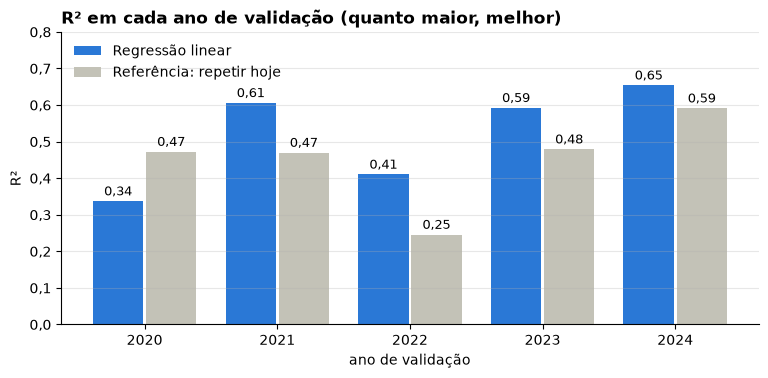

,MAE,RMSE,R²,RMSE da referência,R² da referência
ano de validação,,,,,
2020,"1,132","1,467","0,337","1,309","0,472"
2021,"1,162","1,780","0,606","2,064","0,470"
2022,"1,989","3,593","0,410","4,064","0,246"
2023,"2,281","3,538","0,592","3,999","0,479"
2024,"57,717","106,038","0,654","115,252","0,591"


In [28]:
def metricas_regressao(y_real, y_previsto):
    return {
        'MAE': mean_absolute_error(y_real, y_previsto),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_previsto)),
        'R²': r2_score(y_real, y_previsto),
    }


def validar_linear(colunas):
    # Previsões de validação das 5 rodadas; cada rodada treina só com os anos anteriores
    partes = []
    for ano, idx_e, idx_v in RODADAS:
        estudo, validacao = treino.loc[idx_e], treino.loc[idx_v]
        modelo = LinearRegression().fit(estudo[colunas], estudo['incidencia_em_4_sem'])
        partes.append(pd.DataFrame({'ano': ano, 'real': validacao['incidencia_em_4_sem'],
                                    'previsto': modelo.predict(validacao[colunas]),
                                    'referencia': validacao['incidencia']}))
    return pd.concat(partes)


def por_ano_linear(previsoes):
    linhas = []
    for ano, g in previsoes.groupby('ano'):
        linhas.append({'ano de validação': str(ano), **metricas_regressao(g['real'], g['previsto']),
                       'RMSE da referência': np.sqrt(mean_squared_error(g['real'], g['referencia'])),
                       'R² da referência': r2_score(g['real'], g['referencia'])})
    return pd.DataFrame(linhas).set_index('ano de validação')


def resumo_linear(previsoes):
    anos = por_ano_linear(previsoes)
    return {'RMSE (validação)': np.sqrt(mean_squared_error(previsoes['real'], previsoes['previsto'])),
            'MAE (validação)': mean_absolute_error(previsoes['real'], previsoes['previsto']),
            'R² médio por ano': anos['R²'].mean(),
            'anos em que vence a referência': int((anos['RMSE'] < anos['RMSE da referência']).sum())}


validacao_linear_base = validar_linear(FEATURES_LINEAR)
anos_linear = por_ano_linear(validacao_linear_base)
rmse_validacao_linear = resumo_linear(validacao_linear_base)['RMSE (validação)']
rmse_validacao_ref = np.sqrt(mean_squared_error(validacao_linear_base['real'], validacao_linear_base['referencia']))
print(f'RMSE com todas as previsões da validação: modelo {br(rmse_validacao_linear, 3)} | referência {br(rmse_validacao_ref, 3)}')
print(f"R² do modelo nas 5 rodadas: de {br(anos_linear['R²'].min(), 3)} a {br(anos_linear['R²'].max(), 3)}")
print('Anos em que o modelo teve RMSE menor que a referência:',
      int((anos_linear['RMSE'] < anos_linear['RMSE da referência']).sum()), 'de', len(anos_linear),
      '| ano em que a referência foi melhor:', list(anos_linear.index[anos_linear['RMSE'] >= anos_linear['RMSE da referência']]))

fig, ax = plt.subplots(figsize=(9, 3.8))
posicoes = np.arange(len(anos_linear))
b1 = ax.bar(posicoes - 0.2, anos_linear['R²'], width=0.38, color='#2a78d6', label='Regressão linear')
b2 = ax.bar(posicoes + 0.2, anos_linear['R² da referência'], width=0.38, color='#c3c2b7', label='Referência: repetir hoje')
ax.bar_label(b1, labels=[br(v, 2) for v in anos_linear['R²']], padding=2, fontsize=9)
ax.bar_label(b2, labels=[br(v, 2) for v in anos_linear['R² da referência']], padding=2, fontsize=9)
ax.set_xticks(posicoes, anos_linear.index)
ax.set_xlabel('ano de validação')
ax.set_ylabel('R²')
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(lambda valor, _: br(valor, 1))
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='upper left')
ax.set_title('R² em cada ano de validação (quanto maior, melhor)', loc='left', fontweight='bold')
plt.show()
tabela(anos_linear, casas=3, titulo='Regressão linear em cada rodada de validação')

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **O modelo venceu a referência em 4 dos 5 anos** de validação; só em 2020 a referência teve RMSE menor.
- Com todas as previsões da validação juntas, o RMSE do modelo é 47,762, contra 51,917 da referência.
- **A qualidade muda de um ano para outro:** o R² variou de 0,337 a 0,654. O modelo funciona em todos os anos, mas não com a mesma precisão. Em 2024, ano da epidemia extrema, os erros absolutos são muito maiores (RMSE de 106,038), embora o R² tenha sido o mais alto.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

Nos 5 "simulados", o modelo foi melhor que o palpite simples em 4. Ele é consistente, mas a nota varia bastante de um ano para outro.

</div>

### 4.3 Teste da hipótese: quanto cada grupo de variáveis ajuda

A hipótese (seção 1.3) diz que a incidência recente e o clima ajudam a prever. Para testá-la, repetimos a validação cruzada tirando um grupo de variáveis por vez. Se o erro sobe quando um grupo sai, esse grupo ajuda. O objetivo aqui é **medir a contribuição** de cada grupo; as variáveis do modelo foram fixadas antes, na seção 1.

In [29]:
GRUPOS_LINEAR = {
    'Completo (5 variáveis)': FEATURES_LINEAR,
    'Sem o clima': ['incidencia', 'incidencia_1sem_antes', 'incidencia_2sem_antes'],
    'Sem as semanas anteriores': ['incidencia', 'tempmed', 'umidmed'],
    'Só a incidência de hoje': ['incidencia'],
    'Só o clima': ['tempmed', 'umidmed'],
}
anos_completo = por_ano_linear(validacao_linear_base)
linhas = {}
for nome, colunas in GRUPOS_LINEAR.items():
    prev_g = validacao_linear_base if nome.startswith('Completo') else validar_linear(colunas)
    anos_g = por_ano_linear(prev_g)
    linhas[nome] = {**resumo_linear(prev_g),
                    'anos em que é melhor que o completo': np.nan if nome.startswith('Completo')
                    else int((anos_g['RMSE'] < anos_completo['RMSE']).sum())}
hipotese_linear = pd.DataFrame(linhas).T
rmse_completo = hipotese_linear.loc['Completo (5 variáveis)', 'RMSE (validação)']
hipotese_linear['RMSE em relação ao completo'] = (hipotese_linear['RMSE (validação)'] / rmse_completo - 1) * 100
print('Variação do RMSE ao tirar cada grupo (%):',
      hipotese_linear['RMSE em relação ao completo'].drop('Completo (5 variáveis)').round(1).to_dict())
tabela(hipotese_linear, casas=3, titulo='Teste da hipótese na regressão linear (validação cruzada, só treino)').format(
    '{:.0f}', subset=['anos em que vence a referência', 'anos em que é melhor que o completo'], na_rep='—').format(
    lambda v: br(v, 1) + '%', subset=['RMSE em relação ao completo'])

Variação do RMSE ao tirar cada grupo (%): {'Sem o clima': -1.9, 'Sem as semanas anteriores': 6.7, 'Só a incidência de hoje': 6.7, 'Só o clima': 98.4}


,RMSE (validação),MAE (validação),R² médio por ano,anos em que vence a referência,anos em que é melhor que o completo,RMSE em relação ao completo
Completo (5 variáveis),"47,762","12,993","0,520",4,—,"0,0%"
Sem o clima,"46,870","12,834","0,504",4,2,"-1,9%"
Sem as semanas anteriores,"50,973","14,212","0,529",4,2,"6,7%"
Só a incidência de hoje,"50,943","14,302","0,506",5,1,"6,7%"
Só o clima,"94,761","24,309","-0,283",0,0,"98,4%"


<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **A incidência recente é o que mais ajuda.** Só com o clima o modelo não serve: o RMSE quase dobra (+98,4%) e o R² médio fica negativo (−0,283), pior do que chutar a média. Sem as semanas anteriores, o RMSE sobe 6,7%.
- **O clima quase não ajuda a prever o número de casos.** Sem ele, o RMSE da validação até cai 1,9%, puxado por 2024; mas o modelo completo é melhor em 3 dos 5 anos e tem R² médio maior (0,520 contra 0,504). O efeito do clima na regressão linear é pequeno e instável.
- **A hipótese se confirma em parte:** a incidência recente é a pista principal; o clima tem papel pequeno aqui. Na regressão logística o clima pesa muito mais (seção 5.3).

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

Tiramos uma "pista" de cada vez e vemos se o modelo piora. Sem os casos recentes, ele fica perdido; sem o clima, quase não faz diferença para estimar o número de casos.

</div>

### 4.4 Métricas no teste: MAE, RMSE e R²

| Métrica | Definição técnica | Em palavras simples | Melhor quando |
|---|---|---|---|
| **MAE** | média do erro absoluto, em casos por 100 mil | em média, quanto a previsão erra | menor |
| **RMSE** | raiz da média dos erros ao quadrado, em casos por 100 mil | como o MAE, mas castiga mais os erros grandes | menor |
| **R²** | proporção da variação do alvo explicada pelo modelo | 1 = acerta tudo; 0 = igual a chutar sempre a média | maior |

Para saber se o modelo realmente ajuda, comparamos com uma **referência simples**: supor que a incidência daqui a 4 semanas será igual à de hoje.

In [30]:
tabela_linear = pd.DataFrame({
    'Regressão linear — teste': metricas_regressao(y_teste_lin, prev_linear),
    'Referência (repetir a incidência de hoje) — teste': metricas_regressao(y_teste_lin, teste['incidencia']),
    'Regressão linear — treino': metricas_regressao(y_treino_lin, modelo_linear.predict(X_treino_lin)),
}).T
tabela(tabela_linear, casas=3, titulo='Métricas da regressão linear')

,MAE,RMSE,R²
Regressão linear — teste,"10,685","16,426","0,774"
Referência (repetir a incidência de hoje) — teste,"11,432","21,118","0,626"
Regressão linear — treino,"12,277","35,749","0,797"


In [31]:
# Erro por município: em casos por 100 mil e convertido em casos por semana
resultado_linear = teste[['municipio_nome', 'SE_alvo', 'data_alvo', 'pop', 'incidencia_em_4_sem']].copy()
resultado_linear['previsto'] = prev_linear
resultado_linear['erro_absoluto'] = (resultado_linear['incidencia_em_4_sem'] - resultado_linear['previsto']).abs()

erro_por_municipio = resultado_linear.groupby('municipio_nome').agg(
    incidencia_media_real=('incidencia_em_4_sem', 'mean'),
    MAE=('erro_absoluto', 'mean'),
    populacao=('pop', 'mean'),
).loc[MUNICIPIOS]
erro_por_municipio['MAE_em_casos_por_semana'] = erro_por_municipio['MAE'] * erro_por_municipio['populacao'] / 100_000
print('Previsões negativas no teste:', int((prev_linear < 0).sum()), 'de', len(prev_linear))
tabela(erro_por_municipio.drop(columns='populacao'), casas=1, titulo='Erro da regressão linear por município (teste)')

Previsões negativas no teste: 35 de 430


,incidencia_media_real,MAE,MAE_em_casos_por_semana
municipio_nome,,,
São Paulo,"43,0","10,7","1.306,8"
Osasco,"24,6","13,1","101,5"
Santo André,"6,9","8,1","62,9"
São Bernardo do Campo,"24,5","10,0","82,9"
São Caetano do Sul,"21,8","11,6","19,3"


### 4.5 Visualizações: real × previsto e resíduos

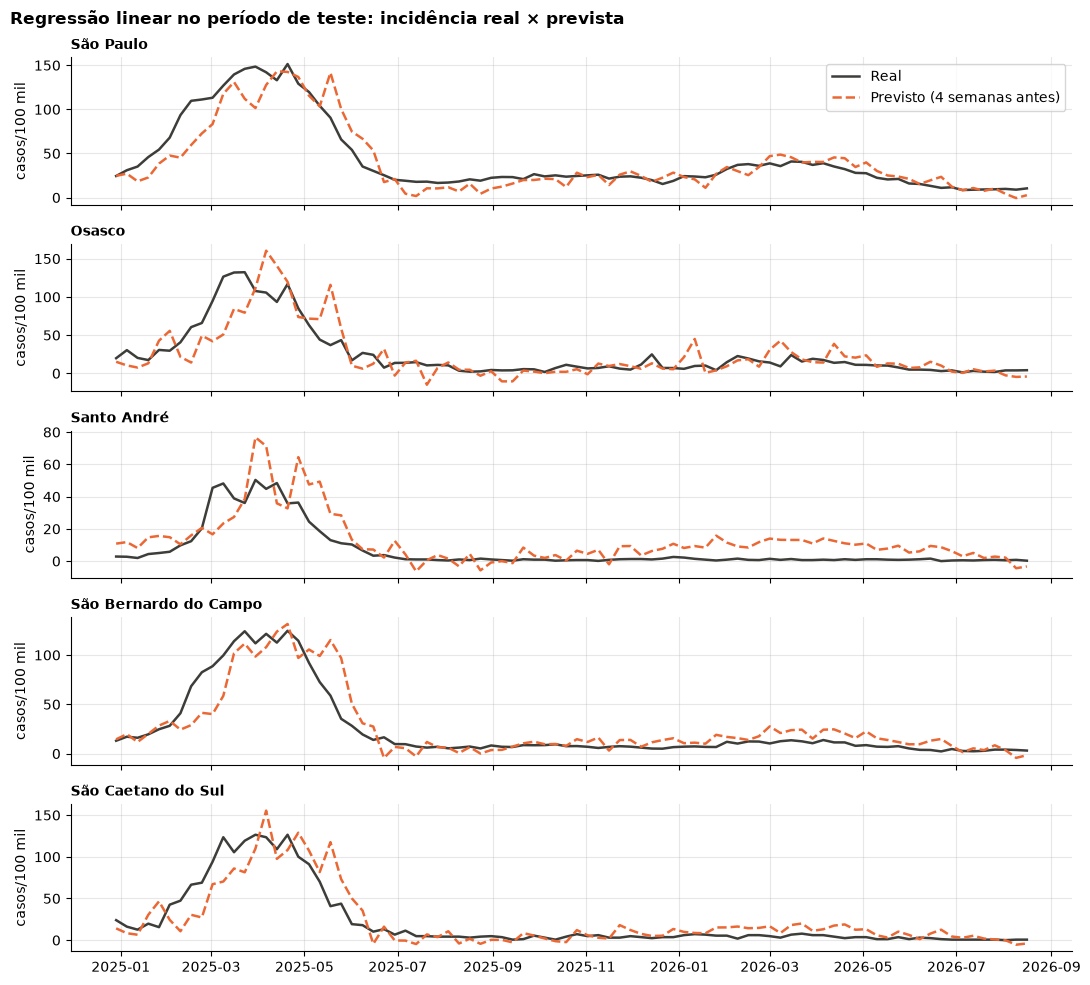

In [32]:
fig, eixos = plt.subplots(len(MUNICIPIOS), 1, figsize=(11, 10), sharex=True)
for ax, mun in zip(eixos, MUNICIPIOS):
    d = resultado_linear[resultado_linear['municipio_nome'] == mun]
    ax.plot(d['data_alvo'], d['incidencia_em_4_sem'], color='#3d3d3a', linewidth=1.8, label='Real')
    ax.plot(d['data_alvo'], d['previsto'], color='#eb6834', linewidth=1.8, linestyle='--', label='Previsto (4 semanas antes)')
    ax.set_title(mun, loc='left', fontsize=10, fontweight='bold')
    ax.set_ylabel('casos/100 mil')
eixos[0].legend(loc='upper right')
fig.suptitle('Regressão linear no período de teste: incidência real × prevista', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como ler o gráfico**

A linha **cinza** é o que aconteceu de verdade. A linha **laranja tracejada** é o que o modelo tinha previsto **4 semanas antes**. Quanto mais as duas linhas se sobrepõem, melhor a previsão. Cada faixa tem sua própria escala.

</div>

Resíduos no teste: mediana -2,03 | média -0,98
Previsões com erro de até 10 casos por 100 mil: 65,8%
Maior previsão abaixo do real: 75,7 | maior previsão acima do real: 78,8


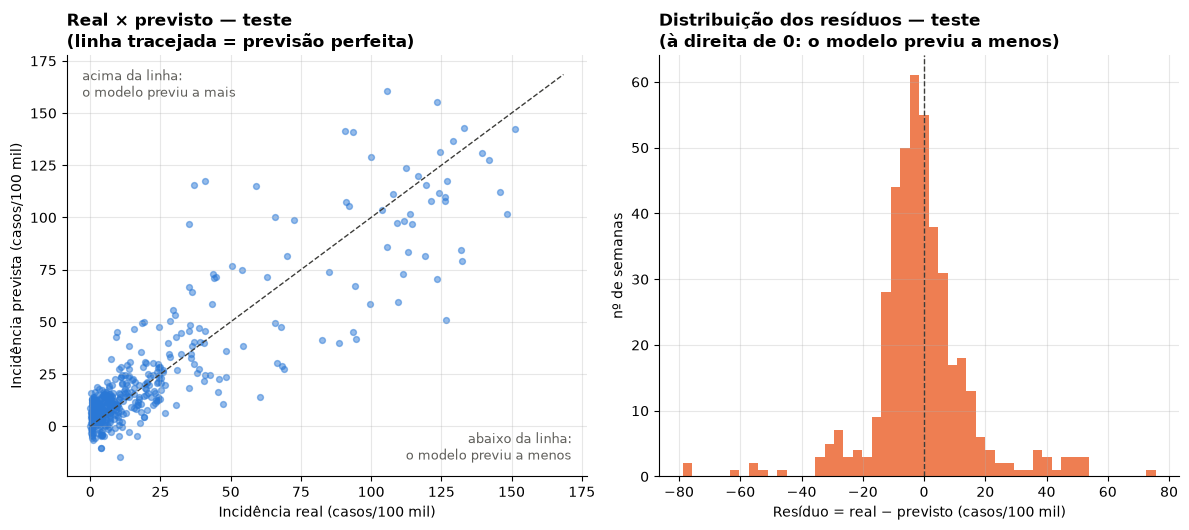

In [33]:
residuos = y_teste_lin - prev_linear  # resíduo = real − previsto
print(f'Resíduos no teste: mediana {br(residuos.median())} | média {br(residuos.mean())}')
print(f'Previsões com erro de até 10 casos por 100 mil: {br(100 * (residuos.abs() <= 10).mean(), 1)}%')
print(f'Maior previsão abaixo do real: {br(residuos.max(), 1)} | maior previsão acima do real: {br(-residuos.min(), 1)}')

fig, eixos = plt.subplots(1, 2, figsize=(12, 5.4))
ax = eixos[0]
ax.scatter(y_teste_lin, prev_linear, s=18, alpha=0.5, color='#2a78d6')
limite = max(y_teste_lin.max(), prev_linear.max()) * 1.05
ax.plot([0, limite], [0, limite], color='#3d3d3a', linestyle='--', linewidth=1)
ax.text(0.03, 0.97, 'acima da linha:\no modelo previu a mais', transform=ax.transAxes, va='top', fontsize=9, color='#5f5e5a')
ax.text(0.97, 0.03, 'abaixo da linha:\no modelo previu a menos', transform=ax.transAxes, ha='right', va='bottom',
        fontsize=9, color='#5f5e5a')
ax.set_xlabel('Incidência real (casos/100 mil)')
ax.set_ylabel('Incidência prevista (casos/100 mil)')
ax.set_title('Real × previsto — teste\n(linha tracejada = previsão perfeita)', loc='left', fontweight='bold')

ax = eixos[1]
ax.hist(residuos, bins=50, color='#eb6834', alpha=0.85)
ax.axvline(0, color='#3d3d3a', linestyle='--', linewidth=1)
ax.set_xlabel('Resíduo = real − previsto (casos/100 mil)')
ax.set_ylabel('nº de semanas')
ax.set_title('Distribuição dos resíduos — teste\n(à direita de 0: o modelo previu a menos)', loc='left', fontweight='bold')
fig.tight_layout()
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como ler os gráficos**

**À esquerda:** cada ponto é uma semana do teste. Pontos sobre a linha tracejada são previsões perfeitas. **À direita:** o **resíduo** é o erro de cada previsão (real − previsto). Barras perto de 0 são acertos; à direita de 0, o modelo previu menos casos do que aconteceram; à esquerda, previu mais.

</div>

### 4.6 Interpretação

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como o modelo se saiu**

- **Desempenho no teste (2025–2026):** o modelo erra em média **10,7 casos por 100 mil habitantes** (MAE = 10,685), com RMSE de 16,426 e **R² = 0,774**, ou seja, explica cerca de 77% da variação da incidência 4 semanas à frente.
- **Comparação com a referência:** o modelo foi melhor que simplesmente repetir a incidência de hoje nas três métricas: MAE 10,685 contra 11,432, RMSE 16,426 contra 21,118 e R² 0,774 contra 0,626. O maior ganho está no RMSE, que pesa mais os erros grandes. Isso indica que o modelo erra menos do que a referência nas mudanças fortes de incidência, quando repetir a semana atual falha mais.
- **Robustez:** na validação cruzada (4.2), o modelo venceu a referência em 4 dos 5 anos, com R² de 0,337 a 0,654: funciona em todos os anos, mas a qualidade varia.
- **Treino × teste:** o R² do treino (0,797) é próximo do R² do teste (0,774), então não há sinal de sobreajuste (*overfitting*). O MAE e o RMSE do treino são maiores principalmente porque o treino inclui o pico extremo de 2024, quando os erros absolutos ficam maiores.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**O que os coeficientes dizem**

- Os três coeficientes de incidência (1,745; −0,285; −0,664) precisam ser lidos juntos, porque as três variáveis são muito correlacionadas (correlação de 0,944 a 0,982, seção 3.5). A soma deles é 0,796, e dá para reescrever a parte da incidência como:
  `0,796 × incidência de hoje + 0,285 × (hoje − 1 semana antes) + 0,664 × (hoje − 2 semanas antes)`.
- **Temperatura média:** a cada +1 °C na semana t, a incidência prevista sobe 1,302 por 100 mil habitantes, mantidas as demais variáveis.
- **Umidade média:** a cada +1 ponto percentual, a incidência prevista sobe 0,732 por 100 mil habitantes, mantidas as demais variáveis.
- O intercepto (−79,918) seria a previsão com todas as entradas iguais a zero (inclusive temperatura de 0 °C e umidade de 0%), situação que não acontece. Por isso ele não tem interpretação prática.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

O modelo pensa assim: **"parto de uns 80% dos casos de hoje e somo a tendência"**. Se os casos vêm subindo nas últimas semanas, a previsão sobe; se vêm caindo, a previsão cai. Semanas mais quentes e mais úmidas empurram a previsão um pouco para cima.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Onde o modelo erra**

- Nas subidas do início de 2025, a linha prevista fica abaixo da real em São Paulo, Osasco, São Bernardo do Campo e São Caetano do Sul: o modelo **reage à alta com atraso**.
- Por ser um modelo único para os 5 municípios, ele não se ajusta bem a cada cidade. Em Santo André, nas semanas de baixa de 2026, a previsão fica claramente acima do real, que se mantém perto de 1 caso por 100 mil.
- Em números de casos, o erro médio em São Paulo equivale a cerca de 1.307 casos por semana.
- **Resíduos:** a mediana é −2,03, ou seja, nas semanas comuns o modelo tende a prever um pouco **acima** do real. Os resíduos grandes ficam à direita de 0 (previsões abaixo do real), nas subidas. 65,8% das previsões erram até 10 casos por 100 mil.
- **35 das 430 previsões do teste foram negativas**, o que é impossível para uma incidência. É uma limitação da regressão linear: ao exibir a previsão, valores negativos devem ser tratados como zero.

</div>

---
<a id="secao5"></a>
## 5. Regressão logística: implementação, matriz de confusão, precisão, recall e F1

**Pergunta 2:** qual é a probabilidade de o município estar acima do limiar epidêmico daqui a 4 semanas?

### 5.1 Implementação

As variáveis estão em escalas muito diferentes (incidência pode passar de 100, umidade fica perto de 80 e a variável 0/1 vai só até 1). Por isso padronizamos as entradas com o `StandardScaler`, ajustado **somente no treino**. Assim os coeficientes ficam comparáveis entre si. O limiar do alerta é definido na seção 5.2, com a validação cruzada.

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

A regressão logística também usa pesos, mas em vez de um número de casos ela devolve uma **probabilidade** entre 0 e 1 (0% a 100%). Se a probabilidade passar do **limiar**, o modelo "toca o alarme": prevê semana epidêmica. O limiar é escolhido nos simulados (validação cruzada), não na prova.

</div>

In [34]:
X_treino_log = treino[FEATURES_LOGISTICA]
y_treino_log = treino['epidemica_em_4_sem']
X_teste_log = teste[FEATURES_LOGISTICA]
y_teste_log = teste['epidemica_em_4_sem']

padronizador = StandardScaler()
X_treino_log_pad = padronizador.fit_transform(X_treino_log)  # média e desvio calculados só no treino
X_teste_log_pad = padronizador.transform(X_teste_log)        # teste só é transformado

modelo_logistico = LogisticRegression(max_iter=1000)
modelo_logistico.fit(X_treino_log_pad, y_treino_log)
prob_teste = modelo_logistico.predict_proba(X_teste_log_pad)[:, 1]  # probabilidade de semana epidêmica

coef_logistica = pd.DataFrame({
    'variável': FEATURES_LOGISTICA,
    'desvio-padrão no treino': padronizador.scale_,
    'coeficiente': modelo_logistico.coef_[0],
    'razão de chances (por 1 desvio-padrão)': np.exp(modelo_logistico.coef_[0]),
})
tabela(coef_logistica, casas=3, esconder_indice=True, titulo='Coeficientes da regressão logística')

variável,desvio-padrão no treino,coeficiente,razão de chances (por 1 desvio-padrão)
incidencia,"79,279","2,794","16,345"
incidencia_1sem_antes,"79,281","2,084","8,034"
incidencia_2sem_antes,"79,284","1,329","3,779"
tempmed,"2,781","1,425","4,156"
umidmed,"8,295","0,690","1,993"
acima_limiar_hoje,"0,388","1,171","3,226"


### 5.2 Validação cruzada no tempo: escolha do limiar do alerta

O limiar decide a partir de qual probabilidade o modelo dá o alerta. O valor padrão (0,5) não é necessariamente o melhor, então testamos os limiares de 0,30 a 0,70, de 0,05 em 0,05, nas 5 rodadas de validação (seção 2.6), sem usar o teste.

**Regra de escolha, definida antes de ver os resultados:** maior F1 calculado com todas as previsões da validação juntas. Diferenças menores que 1% contam como empate, e no empate fica o limiar mais próximo do padrão (0,5).

In [35]:
LIMIARES = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]


def validar_logistica(colunas, pesos=None):
    # Probabilidades de validação das 5 rodadas; cada rodada treina (e padroniza) só com os anos anteriores.
    # pesos=None é o modelo padrão; pesos='balanced' dá mais peso às semanas epidêmicas (teste do desbalanceamento)
    partes = []
    for ano, idx_e, idx_v in RODADAS:
        estudo, validacao = treino.loc[idx_e], treino.loc[idx_v]
        pad = StandardScaler().fit(estudo[colunas])
        modelo = LogisticRegression(max_iter=1000, class_weight=pesos).fit(pad.transform(estudo[colunas]),
                                                                            estudo['epidemica_em_4_sem'])
        partes.append(pd.DataFrame({'ano': ano, 'real': validacao['epidemica_em_4_sem'],
                                    'probabilidade': modelo.predict_proba(pad.transform(validacao[colunas]))[:, 1],
                                    'referencia': validacao['acima_limiar_hoje']}))
    return pd.concat(partes)


validacao_logistica = validar_logistica(FEATURES_LOGISTICA)
linhas = []
for limiar in LIMIARES:
    alerta = (validacao_logistica['probabilidade'] >= limiar).astype(int)
    linhas.append({'limiar': limiar,
                   'precisão': precision_score(validacao_logistica['real'], alerta, zero_division=0),
                   'recall': recall_score(validacao_logistica['real'], alerta, zero_division=0),
                   'F1': f1_score(validacao_logistica['real'], alerta, zero_division=0)})
f1_limiares = pd.DataFrame(linhas).set_index('limiar')

# Regra de escolha: maior F1; diferenças menores que 1% são empate e ficam com o limiar mais perto de 0,5
melhor_f1 = f1_limiares['F1'].max()
empatados = f1_limiares.index[f1_limiares['F1'] >= melhor_f1 * 0.99]
LIMIAR = float(min(empatados, key=lambda limiar: abs(limiar - 0.5)))
f1_ref_validacao = f1_score(validacao_logistica['real'], validacao_logistica['referencia'])
print(f"Maior F1 da validação: {br(melhor_f1, 4)} (limiar {br(f1_limiares['F1'].idxmax(), 2)})")
print('Limiares empatados (F1 a menos de 1% do maior):', [br(l, 2) for l in empatados])
print(f"Limiar escolhido: {br(LIMIAR, 2)} | F1 na validação {br(f1_limiares.loc[LIMIAR, 'F1'], 4)}"
      f" | com o limiar 0,50 seria {br(f1_limiares.loc[0.5, 'F1'], 4)}")
print(f'F1 da referência com todas as previsões da validação juntas: {br(f1_ref_validacao, 4)}')

exibicao = f1_limiares.copy()
exibicao.index = [br(l, 2) + (' (escolhido)' if np.isclose(l, LIMIAR) else '') for l in exibicao.index]
exibicao.index.name = 'limiar'
tabela(exibicao, casas=3, titulo='Validação cruzada: precisão, recall e F1 para cada limiar (só treino)')

Maior F1 da validação: 0,7845 (limiar 0,30)
Limiares empatados (F1 a menos de 1% do maior): ['0,30', '0,35', '0,40', '0,45']
Limiar escolhido: 0,45 | F1 na validação 0,7775 | com o limiar 0,50 seria 0,7735
F1 da referência com todas as previsões da validação juntas: 0,7764


,precisão,recall,F1
limiar,,,
"0,30","0,732","0,845","0,784"
"0,35","0,751","0,820","0,784"
"0,40","0,770","0,799","0,784"
"0,45 (escolhido)","0,773","0,782","0,778"
"0,50","0,790","0,757","0,774"
"0,55","0,803","0,749","0,775"
"0,60","0,811","0,736","0,772"
"0,65","0,814","0,732","0,771"
"0,70","0,838","0,715","0,772"


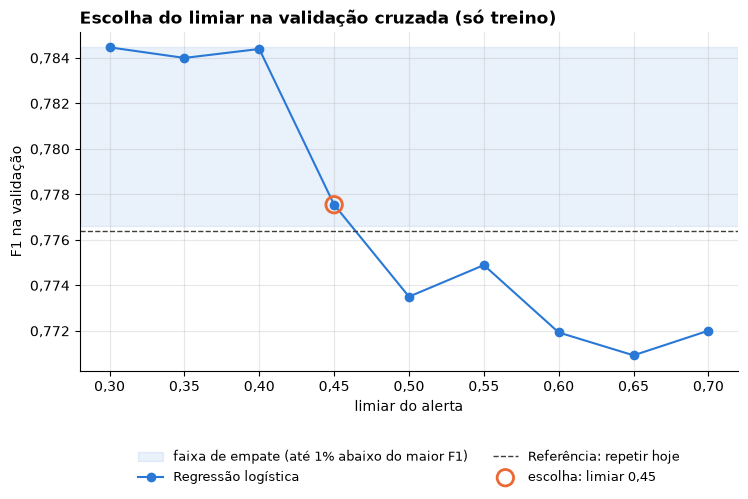

Anos em que o F1 do modelo é maior ou igual ao da referência: 5 de 5


,semanas epidêmicas,precisão,recall,F1,F1 da referência
ano de validação,,,,,
2020,20,"0,526","0,500","0,513","0,500"
2021,2,"0,067","0,500","0,118","0,000"
2022,14,"0,375","0,429","0,400","0,286"
2023,27,"0,594","0,704","0,644","0,593"
2024,176,"0,944","0,858","0,899","0,885"


In [36]:
# F1 em cada limiar, com a faixa de empate e a referência
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.axhspan(melhor_f1 * 0.99, melhor_f1, color='#2a78d6', alpha=0.10, label='faixa de empate (até 1% abaixo do maior F1)')
ax.plot(f1_limiares.index, f1_limiares['F1'], marker='o', color='#2a78d6', label='Regressão logística')
ax.axhline(f1_ref_validacao, color='#3d3d3a', linestyle='--', linewidth=1, label='Referência: repetir hoje')
ax.scatter([LIMIAR], [f1_limiares.loc[LIMIAR, 'F1']], s=140, facecolors='none', edgecolors='#eb6834', linewidths=2,
           zorder=3, label=f'escolha: limiar {br(LIMIAR, 2)}')
ax.xaxis.set_major_formatter(lambda valor, _: br(valor, 2))
ax.yaxis.set_major_formatter(lambda valor, _: br(valor, 3))
ax.set_xlabel('limiar do alerta')
ax.set_ylabel('F1 na validação')
ax.legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.set_title('Escolha do limiar na validação cruzada (só treino)', loc='left', fontweight='bold')
plt.show()

# Estabilidade da escolha ano a ano
linhas = []
for ano, g in validacao_logistica.groupby('ano'):
    alerta = (g['probabilidade'] >= LIMIAR).astype(int)
    linhas.append({'ano de validação': str(ano), 'semanas epidêmicas': int(g['real'].sum()),
                   'precisão': precision_score(g['real'], alerta, zero_division=0),
                   'recall': recall_score(g['real'], alerta, zero_division=0),
                   'F1': f1_score(g['real'], alerta, zero_division=0),
                   'F1 da referência': f1_score(g['real'], g['referencia'], zero_division=0)})
anos_logistica = pd.DataFrame(linhas).set_index('ano de validação')
print('Anos em que o F1 do modelo é maior ou igual ao da referência:',
      int((anos_logistica['F1'] >= anos_logistica['F1 da referência']).sum()), 'de', len(anos_logistica))
tabela(anos_logistica, casas=3, titulo=f'Regressão logística em cada rodada de validação (limiar {br(LIMIAR, 2)})').format(
    '{:.0f}', subset=['semanas epidêmicas'])

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **O limiar padrão (0,5) não era o melhor:** na validação, os limiares de 0,30 a 0,40 tiveram F1 de 0,784, contra 0,774 com 0,50.
- **Escolha pela regra:** o maior F1 foi 0,7845 (limiar 0,30), e os limiares de 0,30 a 0,45 ficaram a menos de 1% dele. Pela regra, fica o mais próximo do padrão: **0,45** (F1 de 0,7775 na validação). Com o limiar 0,50, o F1 seria 0,7735, fora da faixa de empate.
- **A faixa de 0,30 a 0,45 é equivalente no F1, mas muda o equilíbrio:** com 0,30 o modelo dá mais alertas (recall de 0,845) e erra mais neles (precisão de 0,732); com 0,45 fica em precisão 0,773 e recall 0,782.
- **Estabilidade:** com o limiar 0,45, o modelo empatou ou venceu a referência em **5 dos 5 anos** de validação. O F1 varia muito de ano para ano (de 0,118 em 2021, ano com só 2 semanas epidêmicas, a 0,899 em 2024).

</div>

**Desbalanceamento: vale a pena usar `class_weight='balanced'`?**

As semanas epidêmicas são minoria no treino (seção 3.3). Uma forma de lidar com isso, vista em aula, é o parâmetro `class_weight='balanced'`, que dá mais peso às semanas epidêmicas durante o treino. Para decidir **sem olhar o teste**, comparamos as duas versões nas mesmas 5 rodadas de validação, usando a mesma regra (maior F1; diferença menor que 1% é empate, e no empate fica o modelo mais simples, sem pesos). Como os pesos mudam a escala das probabilidades, aqui olhamos os limiares de 0,30 a 0,95.

In [37]:
validacao_balanceada = validar_logistica(FEATURES_LOGISTICA, pesos='balanced')
LIMIARES_AMPLOS = [round(float(l), 2) for l in np.arange(0.30, 0.951, 0.05)]
VERSOES_PESOS = {'Sem pesos (padrão)': validacao_logistica, "Com class_weight='balanced'": validacao_balanceada}

curvas_f1, linhas = {}, {}
for nome, prev in VERSOES_PESOS.items():
    f1s = pd.Series({l: f1_score(prev['real'], (prev['probabilidade'] >= l).astype(int), zero_division=0)
                     for l in LIMIARES_AMPLOS})
    curvas_f1[nome] = f1s
    linhas[nome] = {'AUC (validação)': roc_auc_score(prev['real'], prev['probabilidade']),
                    'chance média dada às semanas não epidêmicas': prev.loc[prev['real'] == 0, 'probabilidade'].mean(),
                    'maior F1 (limiares de 0,30 a 0,95)': f1s.max(),
                    'limiar desse F1': f1s.idxmax(),
                    f'F1 com o limiar {br(LIMIAR, 2)}': f1s[LIMIAR]}
comparacao_pesos = pd.DataFrame(linhas).T
f1_sem, f1_com = comparacao_pesos['maior F1 (limiares de 0,30 a 0,95)']
diferenca = (f1_com - f1_sem) / f1_sem
decisao = "com class_weight='balanced'" if diferenca >= 0.01 else 'sem pesos (padrão)'
print(f"Maior F1 sem pesos: {br(f1_sem, 4)} | com class_weight='balanced': {br(f1_com, 4)}"
      f" | diferença: {br(100 * diferenca, 2)}%")
print(f'Decisão pela regra: fica o modelo {decisao}')
tabela(comparacao_pesos, casas=3, titulo="Validação cruzada: modelo sem pesos × class_weight='balanced' (só treino)")

Maior F1 sem pesos: 0,7845 | com class_weight='balanced': 0,7846 | diferença: 0,02%
Decisão pela regra: fica o modelo sem pesos (padrão)


,AUC (validação),chance média dada às semanas não epidêmicas,"maior F1 (limiares de 0,30 a 0,95)",limiar desse F1,"F1 com o limiar 0,45"
Sem pesos (padrão),"0,961","0,092","0,784","0,300","0,778"
Com class_weight='balanced',"0,962","0,271","0,785","0,950","0,650"


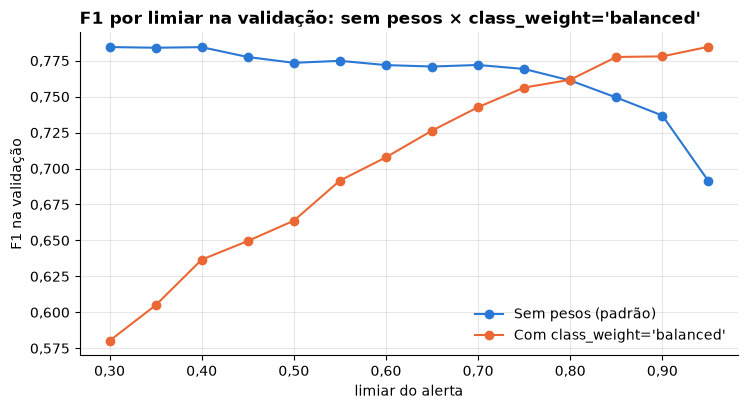

In [38]:
# F1 em cada limiar nas duas versões
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for (nome, f1s), cor in zip(curvas_f1.items(), ['#2a78d6', '#eb6834']):
    ax.plot(f1s.index, f1s.values, marker='o', color=cor, label=nome)
ax.xaxis.set_major_formatter(lambda valor, _: br(valor, 2))
ax.yaxis.set_major_formatter(lambda valor, _: br(valor, 3))
ax.set_xlabel('limiar do alerta')
ax.set_ylabel('F1 na validação')
ax.legend(frameon=False)
ax.set_title("F1 por limiar na validação: sem pesos × class_weight='balanced'", loc='left', fontweight='bold')
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **Os pesos não melhoram o modelo:** o maior F1 na validação foi praticamente o mesmo, 0,7845 sem pesos e 0,7846 com `class_weight='balanced'` (diferença de 0,02%, dentro do empate). A AUC também quase não muda (0,961 contra 0,962).
- **O que os pesos mudam é a escala da chance:** com `balanced`, o modelo dá em média 0,271 de chance às semanas que não foram epidêmicas, contra 0,092 sem pesos. Por isso ele só chega ao mesmo F1 com um limiar muito alto (0,95); com o limiar 0,45, o F1 cairia para 0,650.
- **Decisão:** pela regra, fica o modelo **sem pesos**. Ele é mais simples, tem o mesmo desempenho e dá chances mais próximas da frequência real, o que facilita explicar o alerta para a equipe de saúde. O desbalanceamento continua tratado pela escolha do limiar na validação e pelo uso de precisão, recall e F1 no lugar da acurácia.

</div>

### 5.3 Teste da hipótese: quanto cada grupo de variáveis ajuda

Mesmo teste da seção 4.3, agora para a logística: repetimos a validação cruzada tirando um grupo de variáveis por vez, com o limiar escolhido.

In [39]:
GRUPOS_LOGISTICA = {
    'Completo (6 variáveis)': FEATURES_LOGISTICA,
    'Sem o clima': ['incidencia', 'incidencia_1sem_antes', 'incidencia_2sem_antes', 'acima_limiar_hoje'],
    'Sem as semanas anteriores': ['incidencia', 'tempmed', 'umidmed', 'acima_limiar_hoje'],
    'Sem a situação de hoje (acima_limiar_hoje)': FEATURES_LINEAR,
    'Só o clima': ['tempmed', 'umidmed'],
}
linhas = {}
for nome, colunas in GRUPOS_LOGISTICA.items():
    prev_g = validacao_logistica if nome.startswith('Completo') else validar_logistica(colunas)
    alerta = (prev_g['probabilidade'] >= LIMIAR).astype(int)
    linhas[nome] = {'F1 (validação)': f1_score(prev_g['real'], alerta, zero_division=0),
                    'precisão': precision_score(prev_g['real'], alerta, zero_division=0),
                    'recall': recall_score(prev_g['real'], alerta, zero_division=0)}
hipotese_logistica = pd.DataFrame(linhas).T
tabela(hipotese_logistica, casas=3, titulo=f'Teste da hipótese na regressão logística (validação cruzada, limiar {br(LIMIAR, 2)})')

,F1 (validação),precisão,recall
Completo (6 variáveis),"0,778","0,773","0,782"
Sem o clima,"0,707","0,760","0,661"
Sem as semanas anteriores,"0,787","0,779","0,795"
Sem a situação de hoje (acima_limiar_hoje),"0,789","0,740","0,845"
Só o clima,"0,000","0,000","0,000"


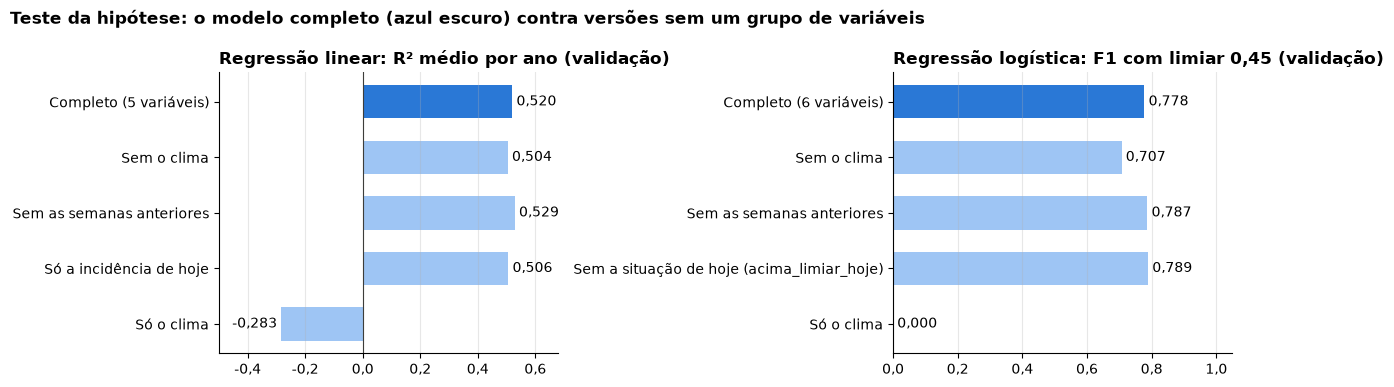

In [40]:
# Gráfico do teste da hipótese nos dois modelos
fig, eixos = plt.subplots(1, 2, figsize=(12.5, 3.9))
r2_grupos = hipotese_linear['R² médio por ano']
eixos[0].barh(r2_grupos.index, r2_grupos.values, color=['#2a78d6'] + ['#9ec5f4'] * (len(r2_grupos) - 1), height=0.6)
eixos[0].bar_label(eixos[0].containers[0], labels=[br(v, 3) for v in r2_grupos.values], padding=3)
eixos[0].axvline(0, color='#3d3d3a', linewidth=0.8)
eixos[0].set_xlim(-0.5, 0.68)
eixos[0].set_title('Regressão linear: R² médio por ano (validação)', loc='left', fontweight='bold')
f1_grupos = hipotese_logistica['F1 (validação)']
eixos[1].barh(f1_grupos.index, f1_grupos.values, color=['#2a78d6'] + ['#9ec5f4'] * (len(f1_grupos) - 1), height=0.6)
eixos[1].bar_label(eixos[1].containers[0], labels=[br(v, 3) for v in f1_grupos.values], padding=3)
eixos[1].set_xlim(0, 1.05)
eixos[1].set_title(f'Regressão logística: F1 com limiar {br(LIMIAR, 2)} (validação)', loc='left', fontweight='bold')
for ax in eixos:
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(lambda valor, _: br(valor, 1))
fig.suptitle('Teste da hipótese: o modelo completo (azul escuro) contra versões sem um grupo de variáveis',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **Na logística, o clima é essencial:** sem ele, o F1 da validação cai de 0,778 para 0,707, e o recall, de 0,782 para 0,661. É o contrário da regressão linear (seção 4.3): o clima ajuda pouco a estimar *quantos* casos haverá, mas ajuda muito a dizer *se* a cidade vai entrar em epidemia.
- **Semanas anteriores e situação de hoje são redundantes aqui:** sem as semanas anteriores (F1 0,787) ou sem `acima_limiar_hoje` (F1 0,789), o desempenho fica praticamente igual, porque a incidência de hoje já carrega quase a mesma informação. Mantivemos as variáveis definidas na hipótese; retirá-las é uma simplificação possível para versões futuras.
- **Só o clima não basta:** com essas duas variáveis, o modelo não acertou nenhuma semana epidêmica com o limiar 0,45. O clima ajuda junto com a incidência, não no lugar dela.
- **Resultado do teste da hipótese:** a incidência recente é a pista principal nos dois modelos (confirmado). O clima tem papel pequeno na previsão do número de casos e papel importante na previsão de epidemia (confirmado em parte).

</div>

### 5.4 Matriz de confusão

A matriz de confusão compara, semana a semana do teste, o que o modelo previu (com o limiar escolhido na seção 5.2) com o que realmente aconteceu.

VP = verdadeiro positivo, VN = verdadeiro negativo, FP = falso positivo (alarme falso), FN = falso negativo (epidemia não antecipada).

Limiar usado: 0,45 (escolhido na validação cruzada)
Matriz de confusão (linhas = real 0/1, colunas = previsto 0/1):
[[276  31]
 [ 22 101]]

Verdadeiros negativos: 276 | Falsos positivos (alarmes falsos): 31
Falsos negativos (epidemias não antecipadas): 22 | Verdadeiros positivos: 101
Semanas realmente epidêmicas: 123 | Alertas dados pelo modelo: 132


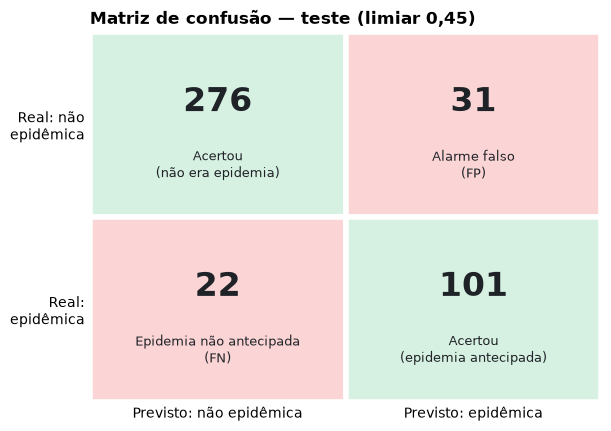

In [41]:
prev_logistica = (prob_teste >= LIMIAR).astype(int)  # alerta = probabilidade >= limiar escolhido na validação
matriz = confusion_matrix(y_teste_log, prev_logistica)  # linhas = real, colunas = previsto
vn, fp, fn, vp = matriz.ravel()
print(f'Limiar usado: {br(LIMIAR, 2)} (escolhido na validação cruzada)')
print('Matriz de confusão (linhas = real 0/1, colunas = previsto 0/1):')
print(matriz)
print(f'\nVerdadeiros negativos: {vn} | Falsos positivos (alarmes falsos): {fp}')
print(f'Falsos negativos (epidemias não antecipadas): {fn} | Verdadeiros positivos: {vp}')
print(f'Semanas realmente epidêmicas: {vp + fn} | Alertas dados pelo modelo: {vp + fp}')

# Mesma matriz, desenhada com explicação em cada quadrado
rotulos = [['Acertou\n(não era epidemia)', 'Alarme falso\n(FP)'],
           ['Epidemia não antecipada\n(FN)', 'Acertou\n(epidemia antecipada)']]
cores = [['#d6f0e1', '#fbd5d5'], ['#fbd5d5', '#d6f0e1']]  # verde = acerto, vermelho = erro
fig, ax = plt.subplots(figsize=(6.6, 4.8))
for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, facecolor=cores[i][j], edgecolor='white', linewidth=4))
        ax.text(j + 0.5, 1 - i + 0.62, str(matriz[i, j]), ha='center', va='center', fontsize=24, fontweight='bold',
                color='#1f2328')
        ax.text(j + 0.5, 1 - i + 0.28, rotulos[i][j], ha='center', va='center', fontsize=9.5, color='#1f2328')
ax.set_xlim(0, 2)
ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5], ['Previsto: não epidêmica', 'Previsto: epidêmica'])
ax.set_yticks([1.5, 0.5], ['Real: não\nepidêmica', 'Real:\nepidêmica'])
ax.tick_params(length=0)
ax.grid(False)
for borda in ax.spines.values():
    borda.set_visible(False)
ax.set_title(f'Matriz de confusão — teste (limiar {br(LIMIAR, 2)})', loc='left', fontweight='bold')
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como ler o gráfico**

Os quadrados **verdes** são acertos e os **vermelhos** são erros. Em cima ficam as semanas que **não** foram epidêmicas; embaixo, as que **foram**. O número grande é quantas semanas caíram em cada caso.

</div>

### 5.5 Precisão, recall e F1

| Métrica | Definição técnica | Em palavras simples |
|---|---|---|
| **Precisão** | VP ÷ (VP + FP) | quando o modelo dá alerta, quantas vezes está certo |
| **Recall** | VP ÷ (VP + FN) | das epidemias que aconteceram, quantas o modelo avisou antes |
| **F1** | média harmônica entre precisão e recall | uma nota única que equilibra as duas |
| **Acurácia** | (VP + VN) ÷ total | quantas previsões acertou no geral |

Como as semanas epidêmicas são minoria (seção 3.3), a acurácia sozinha engana: um modelo que nunca desse alerta já acertaria a maioria das semanas. Por isso o foco está em precisão, recall e F1.

A **referência simples** aqui é repetir a classificação de hoje: se a semana t está acima do limiar, prever que a semana t + 4 também estará.

In [42]:
def metricas_classificacao(y_real, y_previsto):
    return {
        'Acurácia': accuracy_score(y_real, y_previsto),
        'Precisão': precision_score(y_real, y_previsto, zero_division=0),
        'Recall': recall_score(y_real, y_previsto, zero_division=0),
        'F1': f1_score(y_real, y_previsto, zero_division=0),
    }


NOME_LOG_TESTE = f'Regressão logística (limiar {br(LIMIAR, 2)}) — teste'
NOME_REF_TESTE = 'Referência (repetir a classificação de hoje) — teste'
tabela_logistica = pd.DataFrame({
    NOME_LOG_TESTE: metricas_classificacao(y_teste_log, prev_logistica),
    NOME_REF_TESTE: metricas_classificacao(y_teste_log, teste['acima_limiar_hoje']),
    f'Regressão logística (limiar {br(LIMIAR, 2)}) — treino': metricas_classificacao(
        y_treino_log, (modelo_logistico.predict_proba(X_treino_log_pad)[:, 1] >= LIMIAR).astype(int)),
}).T
tabela(tabela_logistica, casas=3, titulo='Métricas da regressão logística')

,Acurácia,Precisão,Recall,F1
"Regressão logística (limiar 0,45) — teste","0,877","0,765","0,821","0,792"
Referência (repetir a classificação de hoje) — teste,"0,865","0,756","0,780","0,768"
"Regressão logística (limiar 0,45) — treino","0,923","0,839","0,721","0,776"


### 5.6 Limiar de decisão, curva sigmoide e curva ROC

O limiar foi escolhido na validação (seção 5.2). A tabela abaixo mostra, **só para informação**, como as métricas do teste mudariam com outros limiares; ela não foi usada para escolher. Diminuir o limiar gera mais alertas: perdem-se menos epidemias, mas aumentam os alarmes falsos.

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

É como regular a sensibilidade de um alarme de incêndio: muito sensível, ele dispara à toa; pouco sensível, pode não disparar quando precisa.

</div>

In [43]:
linhas = []
for limiar in sorted({0.3, 0.4, 0.5, 0.6, 0.7, LIMIAR}):
    previsto = (prob_teste >= limiar).astype(int)
    _, fp_l, fn_l, _ = confusion_matrix(y_teste_log, previsto).ravel()
    linhas.append({'limiar': br(limiar, 2) + (' (escolhido)' if np.isclose(limiar, LIMIAR) else ''),
                   'alarmes falsos (FP)': fp_l,
                   'epidemias não antecipadas (FN)': fn_l,
                   **metricas_classificacao(y_teste_log, previsto)})
tabela(pd.DataFrame(linhas), casas=3, esconder_indice=True, titulo='Métricas no teste para cada limiar (só para informação)')

limiar,alarmes falsos (FP),epidemias não antecipadas (FN),Acurácia,Precisão,Recall,F1
"0,30",41,20,"0,858","0,715","0,837","0,772"
"0,40",34,21,"0,872","0,750","0,829","0,788"
"0,45 (escolhido)",31,22,"0,877","0,765","0,821","0,792"
"0,50",28,24,"0,879","0,780","0,805","0,792"
"0,60",28,25,"0,877","0,778","0,797","0,787"
"0,70",24,27,"0,881","0,800","0,780","0,790"


<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- No teste, os limiares de 0,40 a 0,70 dão F1 parecidos (0,787 a 0,792). O 0,45, escolhido na validação, teve o mesmo F1 do 0,50 (0,792), antecipando 2 semanas epidêmicas a mais (22 não antecipadas, contra 24), com 3 alarmes falsos a mais (31 contra 28).
- Ou seja, nessa faixa o limiar mexe pouco no F1, mas muda o equilíbrio entre alarmes falsos e epidemias não antecipadas.

</div>

**Curva sigmoide: como o modelo transforma as pistas em chance**

A regressão logística primeiro soma as pistas da semana, cada uma multiplicada pelo seu peso, numa **pontuação** *z* (intercepto + soma dos coeficientes × variáveis padronizadas). Depois, a função **sigmoide**, chance = 1 / (1 + e^(−z)), transforma essa pontuação numa probabilidade entre 0 e 1. Como o modelo usa 6 variáveis, o eixo horizontal do gráfico é a pontuação *z*, que junta todas elas.

Intercepto: -1,656 | pontuação z no teste: de -6,68 a 12,37
Com o limiar 0,45, o alerta acontece quando z passa de -0,20
Semanas do teste: 430 | acertos: 377 | erros: 53


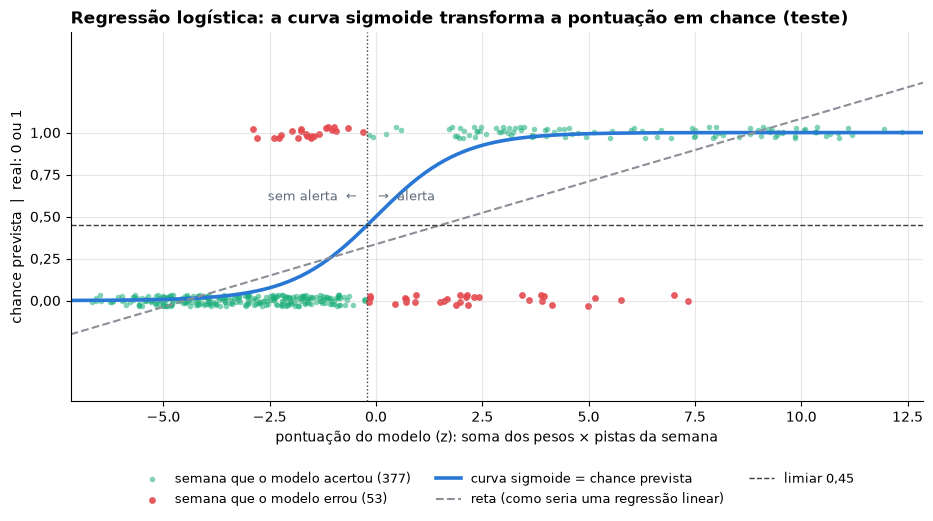

In [44]:
pontuacao_teste = modelo_logistico.decision_function(X_teste_log_pad)  # z de cada semana do teste
assert np.allclose(1 / (1 + np.exp(-pontuacao_teste)), prob_teste)  # a sigmoide de z é a probabilidade do modelo
z_corte = float(np.log(LIMIAR / (1 - LIMIAR)))  # pontuação em que a chance é igual ao limiar
acerto = prev_logistica == y_teste_log.to_numpy()
print(f'Intercepto: {br(modelo_logistico.intercept_[0], 3)} | pontuação z no teste: de {br(pontuacao_teste.min(), 2)}'
      f' a {br(pontuacao_teste.max(), 2)}')
print(f'Com o limiar {br(LIMIAR, 2)}, o alerta acontece quando z passa de {br(z_corte, 2)}')
print(f'Semanas do teste: {len(acerto)} | acertos: {int(acerto.sum())} | erros: {int((~acerto).sum())}')

y_pontos = y_teste_log.to_numpy() + np.random.default_rng(0).uniform(-0.035, 0.035, len(acerto))  # só para não sobrepor
grade = np.linspace(min(pontuacao_teste.min(), -6) - 0.5, max(pontuacao_teste.max(), 6) + 0.5, 400)
inclinacao, intercepto_reta = np.polyfit(pontuacao_teste, y_teste_log, 1)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.scatter(pontuacao_teste[acerto], y_pontos[acerto], s=16, color='#1baf7a', alpha=0.55, linewidths=0,
           label=f'semana que o modelo acertou ({int(acerto.sum())})')
ax.scatter(pontuacao_teste[~acerto], y_pontos[~acerto], s=24, color='#e5484d', alpha=0.9, linewidths=0,
           label=f'semana que o modelo errou ({int((~acerto).sum())})')
ax.plot(grade, 1 / (1 + np.exp(-grade)), color='#2a78d6', linewidth=2.6, label='curva sigmoide = chance prevista')
ax.plot(grade, inclinacao * grade + intercepto_reta, color='#8a8f98', linestyle='--', linewidth=1.5,
        label='reta (como seria uma regressão linear)')
ax.axhline(LIMIAR, color='#3d3d3a', linestyle='--', linewidth=1, label=f'limiar {br(LIMIAR, 2)}')
ax.axvline(z_corte, color='#3d3d3a', linestyle=':', linewidth=1)
ax.text(z_corte - 0.25, 0.62, 'sem alerta  ←', ha='right', va='center', fontsize=9, color='#5f6b7a')
ax.text(z_corte + 0.25, 0.62, '→  alerta', ha='left', va='center', fontsize=9, color='#5f6b7a')
ax.set_xlim(grade.min(), grade.max())
ax.set_ylim(-0.6, 1.6)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.yaxis.set_major_formatter(lambda valor, _: br(valor, 2))
ax.set_xlabel('pontuação do modelo (z): soma dos pesos × pistas da semana')
ax.set_ylabel('chance prevista  |  real: 0 ou 1')
ax.set_title('Regressão logística: a curva sigmoide transforma a pontuação em chance (teste)', loc='left',
             fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False, fontsize=9)
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como ler o gráfico**

Cada ponto é uma semana do teste: fica **em cima (1)** se a semana foi epidêmica e **embaixo (0)** se não foi; a posição na horizontal é a pontuação *z* que o modelo deu 4 semanas antes. A **curva azul** é a sigmoide: ela transforma *z* em chance e nunca sai do intervalo de 0 a 1. A **reta cinza** mostra o que aconteceria com uma regressão linear: ela passa de 0 e de 1, o que não faz sentido para uma probabilidade, e é por isso que usamos a logística para um alvo de sim/não. À direita da linha pontilhada o modelo dá o alerta. Os pontos **vermelhos** são os erros: **em cima e à esquerda** estão as epidemias não antecipadas (FN) e **embaixo e à direita**, os alarmes falsos (FP), os mesmos da matriz de confusão (seção 5.4).

</div>

**Curva ROC e AUC: o modelo em todos os limiares ao mesmo tempo**

A curva ROC mostra, para cada limiar possível, a taxa de verdadeiros positivos (o recall) contra a taxa de falsos positivos (FP ÷ (FP + VN)). A **AUC** (área sob a curva) resume isso num número: 1 = separa perfeitamente semanas epidêmicas de não epidêmicas; 0,5 = igual a sortear. A referência só responde 0 ou 1, então vira um único ponto.

AUC da regressão logística: teste 0,935 | validação cruzada 0,961
AUC da referência (repetir hoje) no teste: 0,840
Limiar 0,45 no teste: taxa de falsos positivos 0,101 | recall 0,821
Referência no teste: taxa de falsos positivos 0,101 | recall 0,780


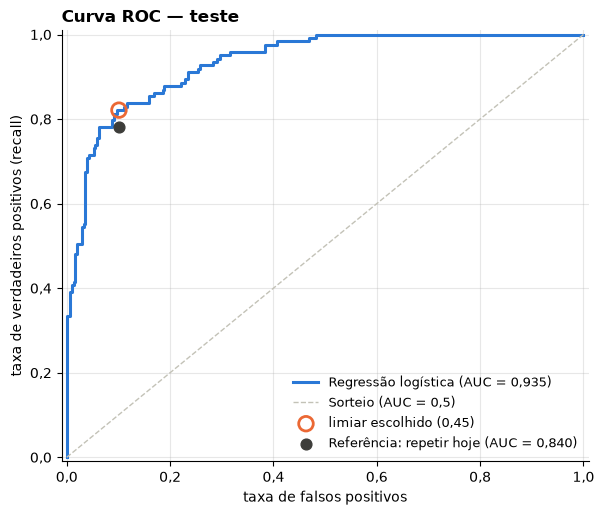

In [45]:
taxa_fp, taxa_vp, _ = roc_curve(y_teste_log, prob_teste)
auc_teste = roc_auc_score(y_teste_log, prob_teste)
auc_referencia = roc_auc_score(y_teste_log, teste['acima_limiar_hoje'])
auc_validacao = roc_auc_score(validacao_logistica['real'], validacao_logistica['probabilidade'])
ponto_modelo = (fp / (fp + vn), vp / (vp + fn))
m_ref = confusion_matrix(y_teste_log, teste['acima_limiar_hoje'])
ponto_referencia = (m_ref[0, 1] / m_ref[0].sum(), m_ref[1, 1] / m_ref[1].sum())
print(f'AUC da regressão logística: teste {br(auc_teste, 3)} | validação cruzada {br(auc_validacao, 3)}')
print(f'AUC da referência (repetir hoje) no teste: {br(auc_referencia, 3)}')
print(f'Limiar {br(LIMIAR, 2)} no teste: taxa de falsos positivos {br(ponto_modelo[0], 3)} | recall {br(ponto_modelo[1], 3)}')
print(f'Referência no teste: taxa de falsos positivos {br(ponto_referencia[0], 3)} | recall {br(ponto_referencia[1], 3)}')

fig, ax = plt.subplots(figsize=(6.8, 5.6))
ax.plot(taxa_fp, taxa_vp, color='#2a78d6', linewidth=2.2, label=f'Regressão logística (AUC = {br(auc_teste, 3)})')
ax.plot([0, 1], [0, 1], color='#c3c2b7', linestyle='--', linewidth=1, label='Sorteio (AUC = 0,5)')
ax.scatter(*ponto_modelo, s=110, facecolors='none', edgecolors='#eb6834', linewidths=2, zorder=3,
           label=f'limiar escolhido ({br(LIMIAR, 2)})')
ax.scatter(*ponto_referencia, s=60, color='#3d3d3a', zorder=3, label=f'Referência: repetir hoje (AUC = {br(auc_referencia, 3)})')
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.xaxis.set_major_formatter(lambda valor, _: br(valor, 1))
ax.yaxis.set_major_formatter(lambda valor, _: br(valor, 1))
ax.set_xlabel('taxa de falsos positivos')
ax.set_ylabel('taxa de verdadeiros positivos (recall)')
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.set_title('Curva ROC — teste', loc='left', fontweight='bold')
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Leitura**

- **AUC de 0,935 no teste** (0,961 na validação cruzada), contra 0,840 da referência. Considerando todos os limiares, o modelo separa bem as semanas epidêmicas das não epidêmicas, e bem melhor que repetir a situação de hoje.
- **No limiar escolhido (0,45),** o modelo tem a mesma taxa de falsos positivos da referência (0,101), mas recall maior (0,821 contra 0,780): com o mesmo número de alarmes falsos, antecipa mais semanas epidêmicas.
- A AUC do teste é um pouco menor que a da validação, mas continua acima de 0,9.

</div>

### 5.7 Onde o modelo erra: quando a situação muda e por município

Separamos as semanas do teste pelo que aconteceu entre a semana t e a semana t + 4.

In [46]:
analise = teste[['municipio_nome', 'acima_limiar_hoje', 'epidemica_em_4_sem']].copy()
analise['previsto'] = prev_logistica
analise['situacao'] = np.select(
    [(analise['acima_limiar_hoje'] == 0) & (analise['epidemica_em_4_sem'] == 0),
     (analise['acima_limiar_hoje'] == 1) & (analise['epidemica_em_4_sem'] == 1),
     (analise['acima_limiar_hoje'] == 0) & (analise['epidemica_em_4_sem'] == 1),
     (analise['acima_limiar_hoje'] == 1) & (analise['epidemica_em_4_sem'] == 0)],
    ['1. Continua abaixo do limiar', '2. Continua acima do limiar',
     '3. Entra em período epidêmico', '4. Sai do período epidêmico'],
    default='?')
analise['acertou'] = analise['previsto'] == analise['epidemica_em_4_sem']
por_situacao = analise.groupby('situacao').agg(semanas=('situacao', 'size'), acertos=('acertou', 'sum'))
tabela(por_situacao, casas=0, titulo=f'Acertos por tipo de situação (teste, limiar {br(LIMIAR, 2)})')

,semanas,acertos
situacao,,
1. Continua abaixo do limiar,276,273
2. Continua acima do limiar,96,96
3. Entra em período epidêmico,27,5
4. Sai do período epidêmico,31,3


In [47]:
linhas = []
for mun in MUNICIPIOS:
    g = analise[analise['municipio_nome'] == mun]
    linhas.append({'município': mun, 'semanas epidêmicas': int(g['epidemica_em_4_sem'].sum()),
                   'alertas': int(g['previsto'].sum()),
                   **{k: v for k, v in metricas_classificacao(g['epidemica_em_4_sem'], g['previsto']).items() if k != 'Acurácia'}})
por_municipio_log = pd.DataFrame(linhas).set_index('município')
tabela(por_municipio_log, casas=3, titulo=f'Regressão logística por município (teste, limiar {br(LIMIAR, 2)})').format(
    '{:.0f}', subset=['semanas epidêmicas', 'alertas'])

,semanas epidêmicas,alertas,Precisão,Recall,F1
município,,,,,
São Paulo,34,44,"0,750","0,971","0,846"
Osasco,33,31,"0,742","0,697","0,719"
Santo André,17,16,"0,812","0,765","0,788"
São Bernardo do Campo,20,21,"0,810","0,850","0,829"
São Caetano do Sul,19,20,"0,750","0,789","0,769"


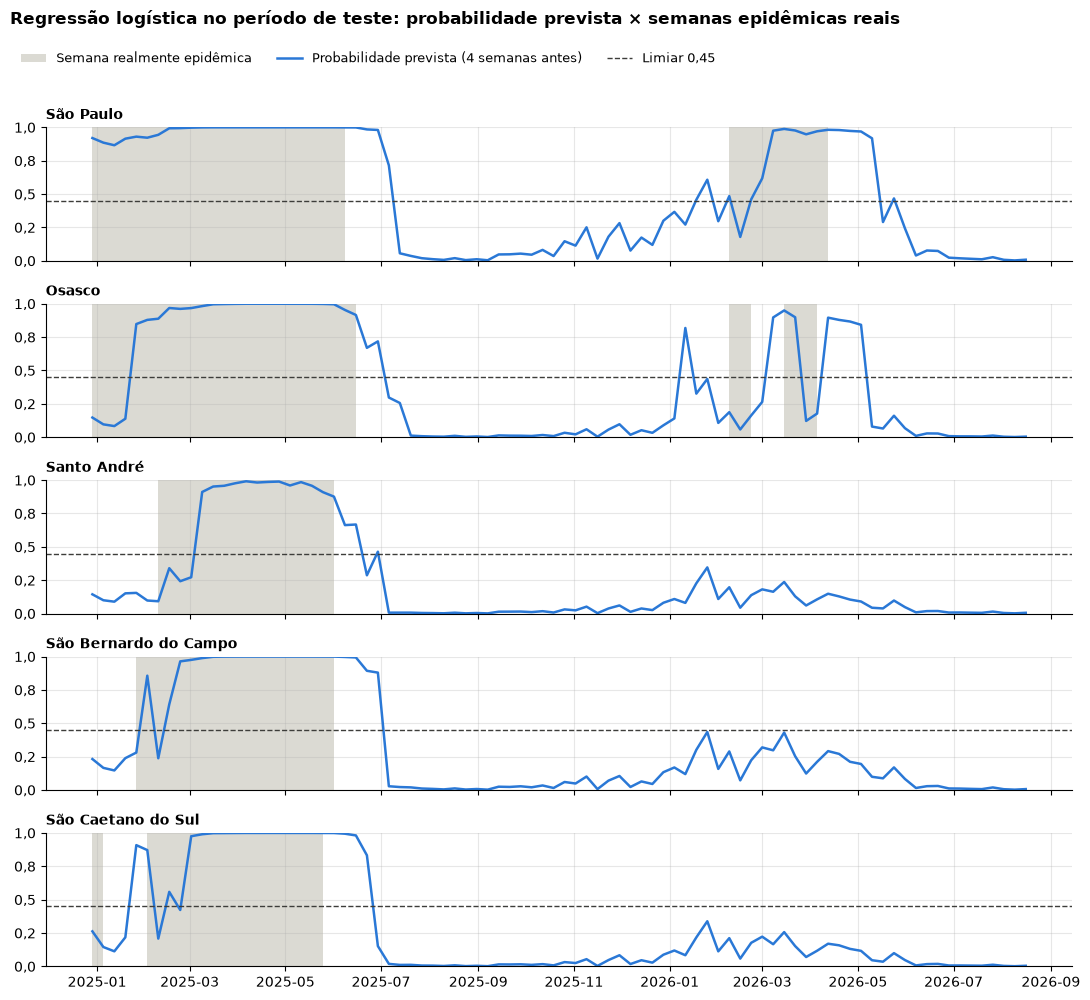

In [48]:
resultado_log = teste[['municipio_nome', 'data_alvo', 'epidemica_em_4_sem']].copy()
resultado_log['probabilidade'] = prob_teste

fig, eixos = plt.subplots(len(MUNICIPIOS), 1, figsize=(11, 10), sharex=True, sharey=True)
for ax, mun in zip(eixos, MUNICIPIOS):
    d = resultado_log[resultado_log['municipio_nome'] == mun]
    ax.fill_between(d['data_alvo'], 0, 1, where=(d['epidemica_em_4_sem'] == 1).to_numpy(),
                    step='mid', color='#c3c2b7', alpha=0.6, linewidth=0, label='Semana realmente epidêmica')
    ax.plot(d['data_alvo'], d['probabilidade'], color='#2a78d6', linewidth=1.8, label='Probabilidade prevista (4 semanas antes)')
    ax.axhline(LIMIAR, color='#3d3d3a', linestyle='--', linewidth=1, label=f'Limiar {br(LIMIAR, 2)}')
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(lambda valor, _: br(valor, 1))
    ax.set_title(mun, loc='left', fontsize=10, fontweight='bold')
fig.suptitle('Regressão logística no período de teste: probabilidade prevista × semanas epidêmicas reais',
             x=0.01, ha='left', y=0.995, fontweight='bold')
itens, nomes = eixos[0].get_legend_handles_labels()
fig.legend(itens, nomes, loc='upper left', bbox_to_anchor=(0.01, 0.965), ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.945))
plt.show()

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como ler o gráfico**

As **faixas cinzas** são as semanas que realmente foram epidêmicas. A **linha azul** é a probabilidade que o modelo deu **4 semanas antes**. O ideal é a linha azul ficar **acima** da linha tracejada (limiar) dentro das faixas cinzas e **abaixo** dela fora delas. Repare que a linha azul costuma subir **depois** que a faixa cinza já começou: é o atraso na virada.

</div>

### 5.8 Interpretação

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Como o modelo se saiu**

- Com o limiar 0,45, escolhido na validação: das **123** semanas que realmente foram epidêmicas, o modelo antecipou **101** (recall = 0,821) e deixou passar 22. Dos **132** alertas, **101** estavam certos (precisão = 0,765) e 31 foram alarmes falsos. Acurácia 0,877 e F1 0,792.
- **Comparação com a referência:** o modelo foi melhor em todas as métricas (F1 0,792 contra 0,768; recall 0,821 contra 0,780; precisão 0,765 contra 0,756), mas a diferença é pequena.
- **Robustez:** na validação cruzada, o modelo empatou ou venceu a referência em 5 dos 5 anos (seção 5.2).
- **Treino × teste:** o F1 do treino (0,776) é parecido com o do teste (0,792), sem sinal de sobreajuste.
- **Curva ROC:** AUC de 0,935 no teste, contra 0,840 da referência (seção 5.6). A curva sigmoide da mesma seção mostra onde ficam os 53 erros.
- **Desbalanceamento:** usar `class_weight='balanced'` não melhorou o F1 nem a AUC na validação; só deslocou as chances para cima (seção 5.2).
- **Por município:** o melhor resultado foi em São Paulo (F1 0,846, recall 0,971) e o pior em Osasco (F1 0,719).

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**O que os coeficientes dizem**

Todos os coeficientes são positivos: incidência alta (hoje e nas semanas anteriores), temperatura e umidade mais altas e o fato de já estar acima do limiar aumentam a probabilidade de semana epidêmica 4 semanas depois. Como as entradas foram padronizadas, a **razão de chances** diz por quanto a chance (*odds*) é multiplicada quando a variável aumenta 1 desvio-padrão, mantidas as demais. A variável de maior peso é a incidência atual (razão de chances de 16,345), seguida da incidência de 1 semana antes (8,034). Para a temperatura, 1 desvio-padrão do treino (cerca de 2,8 °C) multiplica a chance por 4,156. As incidências são muito correlacionadas entre si (seção 3.5), então o peso de cada uma deve ser lido em conjunto.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

Quanto mais casos agora, mais quente e mais úmido, **maior a chance** de a cidade estar em epidemia daqui a um mês. Uma semana cerca de 2,8 °C mais quente, por exemplo, multiplica essa chance por cerca de 4, mantido o resto igual.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Onde estão os erros**

Quando a situação se mantém, o modelo quase não erra: acertou 369 das 372 semanas em que o município continuou abaixo ou continuou acima do limiar. Já nas mudanças ele acerta pouco: antecipou **5 das 27 entradas** em período epidêmico e acertou **3 das 31 saídas**. Dos 53 erros, 50 aconteceram nessas viradas. A referência erra todas as 58 viradas por definição, e é nessas 8 viradas acertadas que está a vantagem do modelo.

</div>

---
<a id="secao6"></a>
## 6. Recomendações de ações fundamentadas nas previsões, com limitações e impactos

### 6.1 Números que fundamentam as recomendações

Os números usados nesta seção vêm das células anteriores e estão reunidos abaixo. Eles também são salvos em `metricas_notebook.json`, que o painel Streamlit usa para conferir que mostra os mesmos resultados do notebook.

REGRESSÃO LINEAR (teste)
  MAE 10,69 | RMSE 16,43 | R² 0,774   (referência: MAE 11,43 | RMSE 21,12 | R² 0,626)
  Venceu a referência em 4 de 5 anos de validação | R² na validação de 0,337 a 0,654
  Erro médio em São Paulo: 1.307 casos por semana
REGRESSÃO LOGÍSTICA (teste, limiar 0,45 escolhido na validação)
  Precisão 0,765 | Recall 0,821 | F1 0,792   (referência: F1 0,768)
  Semanas epidêmicas antecipadas: 101 de 123 | alarmes falsos: 31
  Semanas em que a situação se manteve: 372 | acertos do modelo nelas: 369
  Semanas em que a situação mudou: 58 | acertos do modelo nelas: 8
  Entradas em período epidêmico antecipadas: 5 de 27
  Erros do modelo: 53 no total, 50 deles nas semanas em que a situação mudou


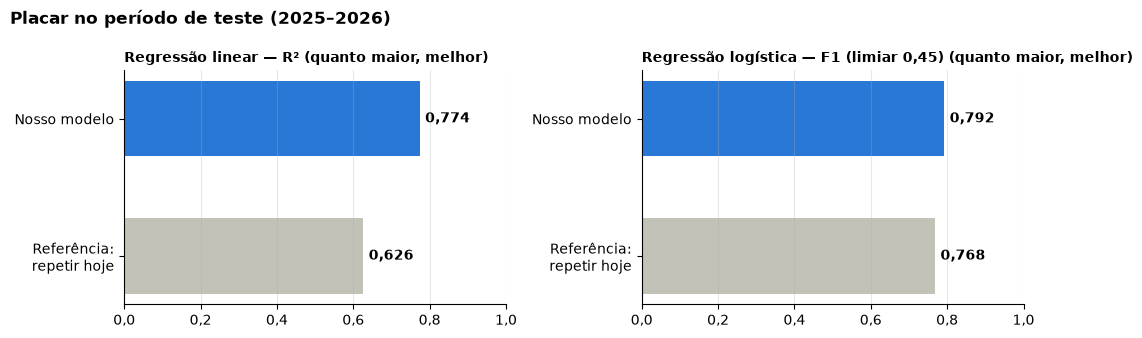

Métricas salvas em metricas_notebook.json


In [49]:
mae_lin, rmse_lin, r2_lin = tabela_linear.loc['Regressão linear — teste', ['MAE', 'RMSE', 'R²']]
mae_ref, rmse_ref, r2_ref = tabela_linear.loc['Referência (repetir a incidência de hoje) — teste', ['MAE', 'RMSE', 'R²']]
log_ = tabela_logistica.loc[NOME_LOG_TESTE]
ref_ = tabela_logistica.loc[NOME_REF_TESTE]
mudancas = analise[analise['situacao'].str.startswith(('3', '4'))]
estaveis = analise[analise['situacao'].str.startswith(('1', '2'))]
entradas = analise[analise['situacao'].str.startswith('3')]

print('REGRESSÃO LINEAR (teste)')
print(f'  MAE {br(mae_lin)} | RMSE {br(rmse_lin)} | R² {br(r2_lin, 3)}'
      f'   (referência: MAE {br(mae_ref)} | RMSE {br(rmse_ref)} | R² {br(r2_ref, 3)})')
print(f"  Venceu a referência em {int((anos_linear['RMSE'] < anos_linear['RMSE da referência']).sum())} de 5 anos de validação"
      f" | R² na validação de {br(anos_linear['R²'].min(), 3)} a {br(anos_linear['R²'].max(), 3)}")
print(f"  Erro médio em São Paulo: {br(erro_por_municipio.loc['São Paulo', 'MAE_em_casos_por_semana'], 0)} casos por semana")
print(f'REGRESSÃO LOGÍSTICA (teste, limiar {br(LIMIAR, 2)} escolhido na validação)')
print(f"  Precisão {br(log_['Precisão'], 3)} | Recall {br(log_['Recall'], 3)} | F1 {br(log_['F1'], 3)}"
      f"   (referência: F1 {br(ref_['F1'], 3)})")
print(f'  Semanas epidêmicas antecipadas: {vp} de {vp + fn} | alarmes falsos: {fp}')
print(f"  Semanas em que a situação se manteve: {len(estaveis)} | acertos do modelo nelas: {int(estaveis['acertou'].sum())}")
print(f"  Semanas em que a situação mudou: {len(mudancas)} | acertos do modelo nelas: {int(mudancas['acertou'].sum())}")
print(f"  Entradas em período epidêmico antecipadas: {int(entradas['acertou'].sum())} de {len(entradas)}")
print(f"  Erros do modelo: {fp + fn} no total, {len(mudancas) - int(mudancas['acertou'].sum())} deles nas semanas em que a situação mudou")

# Placar: nosso modelo × referência simples
fig, eixos = plt.subplots(1, 2, figsize=(10.5, 3.4))
placar = [(eixos[0], 'Regressão linear — R²', [r2_lin, r2_ref]),
          (eixos[1], f'Regressão logística — F1 (limiar {br(LIMIAR, 2)})', [log_['F1'], ref_['F1']])]
for ax, titulo, valores in placar:
    barras = ax.barh(['Nosso modelo', 'Referência:\nrepetir hoje'], valores, color=['#2a78d6', '#c3c2b7'], height=0.55)
    ax.bar_label(barras, labels=[br(v, 3) for v in valores], padding=4, fontweight='bold')
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(lambda valor, _: br(valor, 1))
    ax.invert_yaxis()
    ax.grid(axis='y', visible=False)
    ax.set_title(f'{titulo} (quanto maior, melhor)', loc='left', fontsize=10, fontweight='bold')
fig.suptitle('Placar no período de teste (2025–2026)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

# Salva as métricas principais para o painel Streamlit conferir que mostra os mesmos resultados
metricas_notebook = {
    'linhas_treino': int(len(treino)),
    'linhas_teste': int(len(teste)),
    'limiar_escolhido': LIMIAR,
    'linear_teste': {k: float(v) for k, v in metricas_regressao(y_teste_lin, prev_linear).items()},
    'logistica_teste': {k: float(v) for k, v in metricas_classificacao(y_teste_log, prev_logistica).items()},
    'validacao_rmse_linear': float(rmse_validacao_linear),
    'validacao_f1_logistica': float(f1_limiares.loc[LIMIAR, 'F1']),
}
with open('metricas_notebook.json', 'w', encoding='utf-8') as arquivo:
    json.dump(metricas_notebook, arquivo, ensure_ascii=False, indent=2)
print('Métricas salvas em metricas_notebook.json')

### 6.2 Recomendações de ação baseadas nas previsões

| # | Recomendação | Base nos resultados |
|---|---|---|
| 1 | **Usar a probabilidade da regressão logística como alerta antecipado por município, recalculada toda semana, com limiar 0,45.** Quando a probabilidade passar do limiar, reforçar a orientação à população daquele município (eliminar água parada e recipientes que acumulam água) e dar prioridade às vistorias de ocorrências registradas nele. | No teste, o modelo antecipou 101 das 123 semanas epidêmicas (recall 0,821), e cerca de 3 em cada 4 alertas estavam certos (precisão 0,765). O limiar foi escolhido na validação cruzada, sem olhar o teste. |
| 2 | **Ajustar o limiar ao custo de errar.** O padrão recomendado é 0,45; se a prioridade for não deixar passar semanas epidêmicas, limiares até 0,30 são equivalentes no F1 e dão mais alertas. | Na validação, os limiares de 0,30 a 0,45 ficaram empatados no F1; com 0,30, o recall sobe para 0,845 e a precisão cai para 0,732. |
| 3 | **Usar a regressão linear para dimensionar o esforço, não como número exato.** A previsão serve para a ordem de grandeza e para a tendência (subindo ou caindo). Previsões negativas devem ser mostradas como zero. | Erro médio de 10,7 casos por 100 mil (cerca de 1.307 casos por semana em São Paulo); melhor do que repetir a incidência atual (RMSE 16,4 contra 21,1) e melhor que a referência em 4 dos 5 anos de validação. |
| 4 | **Não depender só do modelo para detectar o início de um surto.** Na época em que a dengue costuma começar a subir, combinar o alerta do modelo com o acompanhamento semanal da incidência e com os alertas oficiais do InfoDengue. | O modelo antecipou só 5 das 27 entradas em período epidêmico. |
| 5 | **Considerar o clima junto com os casos na decisão de alerta.** | Sem o clima, o F1 da logística na validação cai de 0,778 para 0,707 (seção 5.3). |
| 6 | **Retreinar o modelo e revalidar o limiar periodicamente** (por exemplo, a cada temporada), com a mesma validação cruzada no tempo. | O desempenho varia de ano para ano (R² da linear de 0,337 a 0,654 na validação), e o limiar epidêmico do InfoDengue é recalculado (em São Paulo, de 5,4–5,6 em 2018–2020 para 35,2 em 2026). |

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Em palavras simples**

Na prática: **toda semana**, o modelo olha para cada cidade e diz "daqui a um mês, a chance de epidemia é X%". Se passar do limiar de 0,45 (45%), é hora de **avisar a população e priorizar as vistorias** naquela cidade. O número de casos previsto ajuda a ter uma noção do tamanho do problema, mas não deve ser lido como valor exato.

</div>

### 6.3 Limitações

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Limitações**

- **Dados agregados por município e por semana:** o modelo não diz em qual bairro ou imóvel está o risco. Para isso seriam necessários os registros de ocorrências e vistorias do AEGIS.
- **Atraso de notificação:** as 10 semanas mais recentes (SE 34 a 43 de 2026) foram removidas por ainda estarem incompletas. Em uso real, a semana atual sempre está incompleta, e seria preciso usar a estimativa `casos_est` do InfoDengue.
- **2024 foi um ano extremo:** só São Paulo teve 1.263.604 casos notificados, contra no máximo 65.854 por ano entre 2018 e 2023. O modelo aprendeu com esse pico, que pode não se repetir.
- **Período de teste curto e desempenho que varia entre anos:** o teste cobre 2025 e parte de 2026 (430 semanas-município). Na validação cruzada, o R² da linear foi de 0,337 a 0,654 e o F1 da logística, de 0,118 a 0,899, conforme o ano. Os resultados podem mudar em outros anos.
- **Modelo único para 5 municípios da Grande São Paulo:** não se ajusta a cada cidade (na logística, Osasco teve F1 de 0,719, contra 0,846 em São Paulo; a linear superestima Santo André nas semanas de baixa) e não vale automaticamente para outras regiões.
- **Regressão linear:** supõe uma relação linear e gerou 35 previsões negativas em 430.
- **Regressão logística:** erra principalmente nas viradas (início e fim de período epidêmico).
- **Entradas parecidas entre si:** as três incidências têm correlação de 0,944 a 0,982; os pesos de cada uma não devem ser interpretados sozinhos.
- **Classificação recalculada:** a classificação `nivel_inc` das semanas de 2025–2026 veio de versões do modelo do InfoDengue rodadas entre 07/01/2026 e 03/11/2026 (coluna `versao_modelo`), depois de muitas dessas semanas. Em uso real, a classificação disponível na própria semana t pode ser diferente da usada aqui.
- **Poucas variáveis:** só incidência, temperatura e umidade médias. Chuva, saneamento e condições dos imóveis não entraram.
- **Correlação não é causa:** semanas mais quentes coincidem com a época do ano em que a dengue sobe. O modelo não prova que a temperatura causa os casos.

</div>

### 6.4 Impactos

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Impactos positivos**

- **Para o cidadão:** com até 4 semanas de antecedência, a população pode ser orientada antes do pico. No teste, mais de 4 em cada 5 semanas epidêmicas foram antecipadas (101 de 123).
- **Para a gestão das vistorias:** a probabilidade e a incidência prevista permitem comparar municípios e priorizar onde agir primeiro.
- **Como medir e ampliar:** acompanhar todo mês a precisão e o recall das previsões novas, comparando com a referência; incluir mais municípios e, quando existirem, os registros de ocorrências do AEGIS como variáveis.

</div>
<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Riscos**

Os **alarmes falsos** (31 no teste) podem causar desgaste, descrédito e gasto desnecessário. As **epidemias não antecipadas** (22) podem dar falsa sensação de segurança. Por isso a previsão deve ser apresentada como estimativa, com a decisão final tomada por pessoas.

</div>

### 6.5 Conclusão

<div style="box-sizing:border-box; width:100%; max-width:100%; border:1px solid #8c959f; border-radius:6px; padding:10px 18px; margin:10px 0;">

**Conclusão**

- **Pergunta 1:** sim, é possível prever a incidência de 4 semanas depois com erro médio de 10,7 casos por 100 mil e R² de 0,774 no teste, melhor do que repetir a incidência atual. Na validação cruzada, o modelo venceu a referência em 4 dos 5 anos.
- **Pergunta 2:** sim, a regressão logística estima a probabilidade de semana epidêmica com F1 de 0,792 no teste, usando o limiar 0,45 escolhido na validação, um pouco melhor do que repetir a classificação atual. Ela é boa para confirmar a tendência e fraca para antecipar o início de um surto.
- **Hipótese:** a incidência recente é o fator mais forte nos dois modelos. O clima quase não ajuda a estimar o número de casos, mas é importante para prever epidemia. Os modelos devem ser usados como apoio à decisão, nunca como substitutos da vigilância epidemiológica.

</div>

---
<a id="secao7"></a>
## 7. Checklist da entrega

| Item pedido no enunciado | Onde está |
|---|---|
| Notebook executado | este arquivo (`AEGIS_DataScience_GS.ipynb`), com todas as saídas |
| Contexto, perguntas e definição das variáveis-alvo | seção 1 |
| Preparação dos dados | seções 2.1 a 2.5 (fonte, diagnóstico, data wrangling, valores atípicos e conferência) |
| Divisão entre treino e teste, sem vazamento de dados | seção 2.6 (inclui as rodadas de validação cruzada no tempo) |
| Visualizações | seção 3, além dos gráficos das seções 2, 4 e 5 |
| Regressão linear: implementação, MAE, RMSE, R² e interpretação | seção 4 |
| Regressão logística: implementação, matriz de confusão, precisão, recall e F1 | seção 5 |
| Recomendações de ações, com limitações e impactos | seção 6 |
| Base em CSV com indicação da fonte | `dengue_infodengue_2018_2026_5municipios.csv` (original), `dengue_base_tratada.csv` (tratada, seção 2.7) e `fonte_dos_dados.txt` |
| TXT com nomes e RMs dos integrantes | `integrantes.txt` |
| Extra: robustez dos modelos | validação cruzada no tempo (4.2 e 5.2), escolha do limiar e teste do `class_weight` na validação (5.2), teste da hipótese (4.3 e 5.3), curva sigmoide e curva ROC/AUC (5.6) e resultados por município (4.4 e 5.7) |
| Extra: painel interativo | `app.py` (Streamlit), que usa `dengue_base_tratada.csv` e confere os resultados com `metricas_notebook.json` |

<div style="text-align:center; font-size:12px; margin-top:16px;">AEGIS · Global Solution 2026.2 · FIAP · Dados: InfoDengue (Fiocruz/FGV)</div>